# Exportación de datos

In [1]:
# =============================================================================
# IMPORTACIÓN DE LIBRERÍAS
# =============================================================================

"""
Librerías utilizadas durante el proceso de segmentación de canciones.

Se agrupan según su función para mantener el notebook ordenado y facilitar
la identificación de dependencias.

Incluye herramientas para:

- descarga y validación del dataset;
- manipulación y análisis de datos;
- visualización;
- preprocesamiento;
- clustering mediante K-Means;
- evaluación mediante Silhouette Score;
- reducción dimensional mediante PCA;
- almacenamiento de modelos y pipelines.
"""


# =============================================================================
# 1. LIBRERÍAS ESTÁNDAR DE PYTHON
# =============================================================================

import os
import io
import hashlib


# =============================================================================
# 2. DESCARGA DE DATOS
# =============================================================================

import requests


# =============================================================================
# 3. MANIPULACIÓN Y ANÁLISIS DE DATOS
# =============================================================================

import numpy as np
import pandas as pd


# =============================================================================
# 4. VISUALIZACIÓN
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns


# =============================================================================
# 5. PREPROCESAMIENTO
# =============================================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


# =============================================================================
# 6. CLUSTERING
# =============================================================================

from sklearn.cluster import KMeans


# =============================================================================
# 7. EVALUACIÓN DEL CLUSTERING
# =============================================================================

from sklearn.metrics import silhouette_score


# =============================================================================
# 8. REDUCCIÓN DE DIMENSIONALIDAD
# =============================================================================

from sklearn.decomposition import PCA


# =============================================================================
# 9. GUARDADO DE MODELOS Y PIPELINES
# =============================================================================

import joblib


# =============================================================================
# CONFIRMACIÓN
# =============================================================================

print("=" * 70)
print("LIBRERÍAS IMPORTADAS CORRECTAMENTE")
print("=" * 70)

LIBRERÍAS IMPORTADAS CORRECTAMENTE


In [2]:
# obtener hash
url = "https://raw.githubusercontent.com/YorkiOprogramador/Evaluacion1_MachineLearning/main/data/Spotify_Tracks_Dataset.csv"
respuesta = requests.get(url)
hash_calculado = hashlib.sha256(respuesta.content).hexdigest()
print("Hash calculado:", hash_calculado)

Hash calculado: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd


In [3]:
"""
Script para la descarga y validación criptográfica de un set de datos.

Este bloque de código obtiene un archivo CSV directamente desde un
repositorio de GitHub en su formato Raw. Antes de cargarlo en un
DataFrame de Pandas, utiliza la librería hashlib para generar un
hash SHA-256 del contenido descargado y lo compara con un hash de
referencia (previamente auditado).

El objetivo es garantizar la integridad completa del archivo,
asegurando que los datos no hayan sido alterados, corrompidos ni
manipulados externamente, previniendo así la ejecución de modelos
sesgados o vulnerados.
"""

# 1. Configuración de la URL
url = "https://raw.githubusercontent.com/YorkiOprogramador/Evaluacion1_MachineLearning/main/data/Spotify_Tracks_Dataset.csv"

# 2. Define tu Hash esperado
hash_esperado = "b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd"

# 3. Obtener el contenido del archivo desde la web
respuesta = requests.get(url)
contenido_crudo = respuesta.content # Obtenemos los bytes para el hash

# 4. Generar el Hash Criptográfico (SHA-256) del archivo
hash_calculado = hashlib.sha256(contenido_crudo).hexdigest()

# 5. Validación de Seguridad
if hash_calculado == hash_esperado:
    print("Integridad verificada: El archivo es auténtico y no ha sido modificado.")
    # Si es seguro, lo leemos directamente en Pandas
    df = pd.read_csv(io.StringIO(respuesta.text))
    display(df.head())
else:
    print("ALERTA DE SEGURIDAD: El contenido del archivo ha cambiado.")
    print(f"Hash que esperábamos: {hash_esperado}")
    print(f"Hash real obtenido: {hash_calculado}")

Integridad verificada: El archivo es auténtico y no ha sido modificado.


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## tratamiento de duplicados

In [4]:
"""
Script para detectar y analizar registros duplicados basados en 'track_id'.
"""

# 1. Contar el total de duplicados considerando el track id
duplicados_combinados = df.duplicated(['track_id']).sum()
print(f"Total de registros duplicados por track_id: {duplicados_combinados}")

# 2. Visualizar las filas duplicadas para entender la anomalía
# Al usar keep=False, mostramos todas las ocurrencias repetidas juntas para compararlas
df_duplicados = df[df.duplicated(subset=['track_id'], keep=False)]

print("\nDetalle de los primeros registros duplicados (ordenados para comparación):")
display(df_duplicados.sort_values(by=['track_id']).head(10))

Total de registros duplicados por track_id: 24259

Detalle de los primeros registros duplicados (ordenados para comparación):


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,...,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


## Descripción de la fuente de datos

El conjunto de datos utilizado corresponde a **Spotify Tracks Dataset**, un archivo CSV que contiene información sobre canciones, sus características musicales y sus niveles de popularidad.

**Fuente de datos:** [Repositorio de GitHub del proyecto](https://github.com/YorkiOprogramador/Evaluacion1_MachineLearning/tree/main/data).

### Características del dataset

- **Registros originales:** 114.000.
- **Columnas:** 21, incluyendo una columna de índice.
- **Canciones únicas:** 89.741, identificadas mediante `track_id`.
- **Géneros musicales:** 114.
- **Formato:** CSV.

El dataset incluye información como el nombre de la canción, artista, álbum, género, popularidad, duración y características acústicas.

### Aplicación al proyecto

Para desarrollar el modelo de segmentación mediante **K-Means**, se seleccionan nueve características musicales: `duration_ms`, `danceability`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` y `tempo`.

Estas variables permiten agrupar canciones según sus similitudes acústicas, identificando patrones musicales sin utilizar etiquetas previamente definidas.

La variable `popularity` y el género musical se conservan para analizar e interpretar los segmentos obtenidos, pero no participan directamente en la construcción de los clusters.

### Validación y calidad de datos

El archivo se descarga desde GitHub y se verifica mediante **SHA-256** para comprobar su integridad. También se identifican 24.259 registros con identificadores de canciones repetidos, que posteriormente se eliminan para trabajar con una única observación por canción.

Esta preparación permite construir una base adecuada para el análisis y la segmentación musical.

## EDA

**Fuente de datos:** [Repositorio de GitHub del proyecto](https://github.com/YorkiOprogramador/Evaluacion1_MachineLearning/tree/main/data).

El eda para la justificación de este ejercicio se desarrolló en el repositorio adjunto para el encargo 1 de esta materia.

# Preparación de datos para clustering

## Preparar la base exclusiva para segmentación

In [5]:
"""
Preparación de la base para segmentación.

Objetivo:
Construir un conjunto de datos específicamente diseñado para clustering,
donde cada observación represente una única canción y la segmentación se
base exclusivamente en sus características acústicas cuantitativas.

Decisiones metodológicas:

1. Unidad de análisis:
   Se considera una canción única mediante 'track_id'.

   Algunas canciones aparecen asociadas a múltiples géneros en el dataset
   original. Se conserva únicamente la primera ocurrencia para evitar que
   las mismas características acústicas sean contabilizadas varias veces.

   Esta decisión sacrifica parte de la información multigénero, pero evita
   alterar las distribuciones y la formación de clusters.

2. Exclusión de 'popularity':
   Popularity NO participa en la construcción de los clusters.

   Se conservará únicamente como variable externa para analizar posteriormente
   si determinados segmentos presentan mayor o menor popularidad.

3. Exclusión de variables categóricas:
   Variables como:
       - track_genre
       - explicit
       - key
       - mode
       - time_signature

   se excluyen del espacio utilizado por K-Means.

   Aunque algunas podrían codificarse mediante One-Hot Encoding, introducirlas
   modificaría la geometría de la distancia euclidiana utilizada por K-Means.

   En particular, 'track_genre' posee alta cardinalidad y podría provocar que
   los grupos se formen principalmente por diferencias categóricas en lugar
   de perfiles acústicos.

4. Exclusión de 'energy':
   Se elimina por decisión metodológica del equipo debido a su elevada
   redundancia observada con otras características acústicas.

Las variables categóricas y popularity se conservarán posteriormente
para caracterizar los clusters, pero NO para construirlos.
"""


# =========================================================
# 1. Crear copia independiente para clustering
# =========================================================

df_cluster = df.copy()


# =========================================================
# 2. Garantizar una única observación por canción
# =========================================================

registros_iniciales = len(df_cluster)

df_cluster = (
    df_cluster
    .drop_duplicates(
        subset='track_id',
        keep='first'
    )
    .reset_index(drop=True)
)

registros_finales = len(df_cluster)


# =========================================================
# 3. Variables acústicas utilizadas para la segmentación
# =========================================================

features_cluster = [
    'duration_ms',
    'danceability',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]


# =========================================================
# 4. Verificar existencia de columnas
# =========================================================

columnas_faltantes = [
    col for col in features_cluster
    if col not in df_cluster.columns
]

if columnas_faltantes:
    raise ValueError(
        f"Faltan columnas necesarias para clustering: {columnas_faltantes}"
    )


# =========================================================
# 5. Crear matriz destinada exclusivamente a K-Means
# =========================================================

X_cluster = df_cluster[
    features_cluster
].copy()


# =========================================================
# 6. Verificación
# =========================================================

print("=" * 70)
print("BASE PREPARADA PARA SEGMENTACIÓN")
print("=" * 70)

print(f"\nRegistros originales: {registros_iniciales:,}")
print(f"Registros únicos     : {registros_finales:,}")

print(
    f"\nDuplicados eliminados: "
    f"{registros_iniciales - registros_finales:,}"
)

print(
    f"\nCantidad de variables utilizadas por K-Means: "
    f"{len(features_cluster)}"
)

print("\nVariables seleccionadas:")

for variable in features_cluster:
    print(f"  - {variable}")

print(
    "\nIMPORTANTE: popularity y las variables categóricas "
    "NO participan en la creación de los clusters."
)

BASE PREPARADA PARA SEGMENTACIÓN

Registros originales: 114,000
Registros únicos     : 89,741

Duplicados eliminados: 24,259

Cantidad de variables utilizadas por K-Means: 9

Variables seleccionadas:
  - duration_ms
  - danceability
  - loudness
  - speechiness
  - acousticness
  - instrumentalness
  - liveness
  - valence
  - tempo

IMPORTANTE: popularity y las variables categóricas NO participan en la creación de los clusters.


La base fue depurada antes de entrenar K-Means. De los **114.000 registros originales**, se conservaron **89.741 canciones únicas**, eliminando **24.259 registros duplicados** asociados a `track_id` repetidos.

Para construir los clusters se seleccionaron **9 variables acústicas cuantitativas**:

`duration_ms`, `danceability`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` y `tempo`.

Las variables categóricas y `popularity` fueron excluidas de la formación de los clusters, ya que se utilizarán posteriormente solo para caracterizar e interpretar los segmentos obtenidos.

En resumen, esta preparación permite que K-Means trabaje con una sola observación por canción y con variables adecuadas para construir una segmentación basada principalmente en el perfil acústico.

## Configuración del pipeline

In [6]:
# =============================================================================
# PIPELINE DE PREPROCESAMIENTO PARA K-MEANS
# =============================================================================

""""
Pipeline de preprocesamiento utilizado antes de entrenar K-Means.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque prepara las características acústicas seleccionadas para que
puedan ser utilizadas correctamente por el algoritmo K-Means.

El procedimiento realiza los siguientes pasos:

1. Construye un pipeline de preprocesamiento.

2. Imputa posibles valores faltantes utilizando la mediana.

3. Estandariza todas las variables mediante `StandardScaler`.

4. Transforma el conjunto `X_cluster`.

5. Reconstruye los datos procesados como un DataFrame para conservar los
   nombres de las características.

6. Verifica que el preprocesamiento no haya generado valores NaN ni infinitos.

7. Muestra estadísticas básicas para comprobar que la estandarización se
   realizó correctamente.

¿POR QUÉ NO SE APLICA WINSORIZACIÓN?

Durante el análisis exploratorio se observó que los valores extremos
identificados corresponden principalmente a casos plausibles dentro del
dominio musical.

Como el objetivo del clustering es descubrir perfiles diferentes dentro del
catálogo, estos valores se conservan.

Eliminar o limitar esos casos podría reducir artificialmente diferencias
reales entre canciones e incluso ocultar segmentos minoritarios relevantes.

Por esta razón:

    los outliers se conservan
    y posteriormente se analiza su presencia dentro de cada cluster.

¿POR QUÉ SE UTILIZA IMPUTACIÓN POR MEDIANA?

La imputación se incorpora como una medida preventiva frente a posibles
valores faltantes.

Se utiliza la mediana porque es menos sensible que la media a:

- distribuciones asimétricas;
- valores muy altos o muy bajos;
- observaciones extremas.

Esto permite completar eventuales datos faltantes sin modificar de forma
excesiva la distribución de las variables.

¿POR QUÉ SE UTILIZA STANDARDSCALER?

K-Means forma los grupos utilizando distancia euclidiana.

Las variables originales poseen escalas muy diferentes.

Por ejemplo:

    duration_ms
        utiliza valores del orden de cientos de miles.

    tempo
        utiliza valores cercanos a cientos.

    danceability
        utiliza valores entre 0 y 1.

Si se aplicara K-Means directamente sobre estas escalas, las variables con
mayor magnitud numérica podrían dominar el cálculo de las distancias.

`StandardScaler` transforma cada característica para que tenga
aproximadamente:

    media = 0
    desviación estándar = 1

De esta manera, todas las variables pueden participar de forma comparable
en la construcción de los clusters.

¿STANDARDSCALER ELIMINA LOS VALORES EXTREMOS?

No.

StandardScaler cambia la escala de las variables, pero no elimina ni
winsoriza las observaciones extremas.

Por esta razón, todavía pueden aparecer valores estandarizados alejados de
cero, por ejemplo:

    z > 3
    o
    z < -3

Esto es esperado porque los casos extremos reales fueron conservados.

¿POR QUÉ NO SE UTILIZA ONE-HOT ENCODING?

Las variables categóricas fueron excluidas deliberadamente de la formación de
los clusters.

El objetivo es construir una segmentación basada principalmente en el perfil
acústico de las canciones.

Incorporar variables categóricas mediante One-Hot Encoding, especialmente una
variable con muchas categorías como `track_genre`, aumentaría
considerablemente la dimensionalidad y podría hacer que la distancia
euclidiana estuviera más influida por las categorías que por las
características acústicas.

¿QUÉ VALIDACIONES REALIZA EL CÓDIGO?

Después del preprocesamiento se comprueba que:

- no existan valores NaN;
- no existan valores infinitos;
- las dimensiones antes y después del procesamiento sean coherentes;
- las medias estén aproximadamente en 0;
- las desviaciones estándar estén aproximadamente en 1.

También se muestran los valores mínimos y máximos estandarizados para
comprobar que los valores extremos continúan presentes.

¿PARA QUÉ SIRVE ESTE PIPELINE?

El pipeline garantiza que las transformaciones se ejecuten siempre en el
mismo orden:

    Imputación por mediana
              ↓
       StandardScaler
              ↓
     Datos preparados
              ↓
          K-Means

Esto mejora la organización, reproducibilidad y consistencia del proceso de
segmentación.

IMPORTANTE:

El preprocesamiento no busca alterar artificialmente la naturaleza de los
datos.

Su objetivo es preparar las variables para que K-Means pueda comparar
correctamente las características acústicas y formar segmentos de manera
coherente.
"""


# =============================================================================
# 1. CONSTRUCCIÓN DEL PREPROCESADOR
# =============================================================================

preprocessor_clustering = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='median'
            )
        ),
        (
            'scaler',
            StandardScaler()
        )
    ]
)


# =============================================================================
# 2. AJUSTE Y TRANSFORMACIÓN
# =============================================================================

X_cluster_scaled = preprocessor_clustering.fit_transform(
    X_cluster
)


# =============================================================================
# 3. RECONSTRUCCIÓN COMO DATAFRAME
# =============================================================================

X_cluster_scaled_df = pd.DataFrame(
    X_cluster_scaled,
    columns=features_cluster,
    index=X_cluster.index
)


# =============================================================================
# 4. VALIDACIONES
# =============================================================================

if np.isnan(X_cluster_scaled).any():
    raise ValueError(
        "El preprocesamiento generó valores NaN."
    )

if np.isinf(X_cluster_scaled).any():
    raise ValueError(
        "El preprocesamiento generó valores infinitos."
    )


# =============================================================================
# 5. RESULTADOS
# =============================================================================

print("=" * 75)
print("PREPROCESAMIENTO PARA CLUSTERING COMPLETADO")
print("=" * 75)

print(
    f"\nDimensiones originales : "
    f"{X_cluster.shape}"
)

print(
    f"Dimensiones procesadas : "
    f"{X_cluster_scaled_df.shape}"
)


print("\nMedia después de StandardScaler:")

print(
    X_cluster_scaled_df
    .mean()
    .round(4)
)


print("\nDesviación estándar después de StandardScaler:")

print(
    X_cluster_scaled_df
    .std(ddof=0)
    .round(4)
)


print("\nValores mínimos estandarizados:")

print(
    X_cluster_scaled_df
    .min()
    .round(3)
)


print("\nValores máximos estandarizados:")

print(
    X_cluster_scaled_df
    .max()
    .round(3)
)


print(
    "\nNota: valores estandarizados elevados pueden permanecer "
    "porque las observaciones extremas reales fueron conservadas."
)

PREPROCESAMIENTO PARA CLUSTERING COMPLETADO

Dimensiones originales : (89741, 9)
Dimensiones procesadas : (89741, 9)

Media después de StandardScaler:
duration_ms         0.0
danceability       -0.0
loudness           -0.0
speechiness         0.0
acousticness       -0.0
instrumentalness   -0.0
liveness            0.0
valence            -0.0
tempo              -0.0
dtype: float64

Desviación estándar después de StandardScaler:
duration_ms         1.0
danceability        1.0
loudness            1.0
speechiness         1.0
acousticness        1.0
instrumentalness    1.0
liveness            1.0
valence             1.0
tempo               1.0
dtype: float64

Valores mínimos estandarizados:
duration_ms        -2.029
danceability       -3.182
loudness           -7.858
speechiness        -0.772
acousticness       -0.970
instrumentalness   -0.535
liveness           -1.113
valence            -1.786
tempo              -4.053
dtype: float64

Valores máximos estandarizados:
duration_ms         44.3

El preprocesamiento se realizó correctamente sobre las **89.741 canciones y 9 variables seleccionadas**, manteniendo las mismas dimensiones antes y después de la transformación.

Después de aplicar `StandardScaler`, todas las características presentan una **media cercana a 0** y una **desviación estándar cercana a 1**, lo que confirma que las variables quedaron correctamente estandarizadas y pueden ser comparadas en una misma escala para K-Means.

También se observa que algunos valores continúan muy alejados del promedio, por ejemplo:

- `duration_ms` alcanza aproximadamente **+44,34 desviaciones estándar**.
- `speechiness` alcanza **+7,75**.
- `instrumentalness` alcanza **+2,55**.
- `liveness` alcanza **+4,02**.
- `tempo` alcanza **+4,03**.

Esto es coherente con la decisión metodológica de **no eliminar ni winsorizar los valores extremos**, ya que fueron considerados casos plausibles dentro del dominio musical.

En conclusión, el pipeline logró **igualar las escalas sin eliminar la variabilidad original de los datos**, dejando las características correctamente preparadas para aplicar K-Means.

### ¿Qué significa este preprocesamiento para la segmentación?

La estandarización permite que las nueve variables participen en K-Means en
una escala comparable, evitando que una característica tenga mayor peso solo
por utilizar valores numéricos más grandes.

Sin embargo, las canciones que realmente presentan características muy
alejadas del promedio continúan siendo diferentes después del escalamiento.
Por esta razón, esas observaciones pueden influir en la formación de ciertos
clusters y ayudar a identificar perfiles musicales particulares.

En otras palabras, `StandardScaler` elimina el problema de las diferencias de
escala, pero conserva las diferencias reales existentes entre las canciones.

Esto permite que la segmentación considere tanto los comportamientos más
comunes como posibles perfiles extremos o de nicho presentes en el catálogo.

## Exportar archivos de segmentación

In [7]:
# =============================================================================
# EXPORTACIÓN DE DATOS PARA SEGMENTACIÓN
# =============================================================================

"""
Exportación de los datos y objetos necesarios para reproducir posteriormente
el proceso de segmentación.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque guarda en archivos separados los datos utilizados durante el
clustering y el pipeline de preprocesamiento aplicado antes de entrenar
K-Means.

El procedimiento realiza los siguientes pasos:

1. Crea una carpeta llamada `archivos_segmentacion` para almacenar los
   resultados exportados.

2. Genera un identificador común llamado `row_id` para mantener alineadas
   las canciones entre los distintos archivos.

3. Exporta las variables acústicas seleccionadas antes del escalamiento.

4. Exporta las mismas variables después de aplicar el pipeline de
   preprocesamiento.

5. Exporta las variables contextuales que no participaron en la creación
   de los clusters, pero que pueden utilizarse posteriormente para
   interpretar los segmentos.

6. Guarda el pipeline de preprocesamiento mediante `joblib`.

7. Verifica que los tres conjuntos exportados tengan exactamente la misma
   cantidad de observaciones.

¿QUÉ ARCHIVOS SE GENERAN?

1. `X_segmentacion_original.csv`

Contiene las características acústicas seleccionadas en sus unidades
originales, antes de aplicar StandardScaler.

Este archivo permite revisar cómo eran los datos antes del
preprocesamiento.

2. `X_segmentacion_escalado.csv`

Contiene las mismas características después de aplicar:

    imputación por mediana
            ↓
      StandardScaler

Esta es la representación utilizada posteriormente por K-Means para
calcular las distancias y formar los clusters.

3. `contexto_segmentacion.csv`

Contiene información adicional de las canciones que NO fue utilizada para
construir los clusters.

Entre estas variables pueden encontrarse:

    track_id
    artists
    album_name
    track_name
    track_genre
    explicit
    key
    mode
    time_signature
    popularity

Estas columnas sirven posteriormente para caracterizar e interpretar los
segmentos obtenidos.

Por ejemplo, permiten analizar:

- qué géneros predominan en cada cluster;
- qué canciones pertenecen a cada segmento;
- qué popularidad presentan los grupos;
- y qué artistas aparecen dentro de ellos.

4. `preprocessor_clustering.joblib`

Contiene el pipeline utilizado para preparar las variables antes de K-Means.

El archivo conserva:

    SimpleImputer(strategy='median')
            ↓
       StandardScaler

Esto permite aplicar exactamente las mismas transformaciones en futuras
ejecuciones sin tener que volver a definir manualmente el preprocesamiento.

¿PARA QUÉ SIRVE `row_id`?

Los archivos exportados contienen información diferente, pero representan
las mismas canciones.

Por esta razón se genera `row_id`, que funciona como un identificador común
entre:

    X_segmentacion_original.csv
    X_segmentacion_escalado.csv
    contexto_segmentacion.csv

Esto permite relacionar una observación entre los distintos archivos sin
depender del índice interno de pandas.

¿POR QUÉ SE SEPARAN LAS VARIABLES ACÚSTICAS DE LAS VARIABLES CONTEXTUALES?

Las variables acústicas son las que participan directamente en la creación
de los clusters.

En cambio, las variables contextuales se mantienen separadas para evitar
que influyan en la distancia utilizada por K-Means.

De esta forma se conserva una separación clara entre:

    variables utilizadas para SEGMENTAR
                     y
    variables utilizadas para INTERPRETAR

¿QUÉ VALIDACIONES REALIZA EL CÓDIGO?

Al final se utilizan instrucciones `assert` para comprobar que los tres
archivos principales contienen la misma cantidad de observaciones.

Esto permite detectar posibles pérdidas o desalineaciones de registros
durante la exportación.

Si las cantidades fueran diferentes, el código produciría un error antes de
continuar.

¿POR QUÉ ES IMPORTANTE ESTA EXPORTACIÓN?

Guardar estos archivos mejora la reproducibilidad y trazabilidad del
proyecto.

Permite:

- revisar los datos antes y después del preprocesamiento;
- reutilizar el pipeline;
- auditar la información utilizada por K-Means;
- relacionar posteriormente los clusters con información contextual;
- y repetir el proceso sin reconstruir manualmente las transformaciones.

IMPORTANTE:

`contexto_segmentacion.csv` contiene variables que sirven únicamente para
caracterización posterior.

Su presencia en el archivo exportado NO significa que hayan participado en
la creación de los clusters.

La formación de los segmentos continúa basada exclusivamente en las
características acústicas seleccionadas y preprocesadas.
"""


# =========================================================
# 1. Carpeta
# =========================================================

output_folder = 'archivos_segmentacion'

os.makedirs(
    output_folder,
    exist_ok=True
)


# =========================================================
# 2. Identificador común
# =========================================================

row_id = np.arange(
    len(df_cluster)
)


# =========================================================
# 3. Datos originales
# =========================================================

X_original_export = X_cluster.copy()

X_original_export.insert(
    0,
    'row_id',
    row_id
)


# =========================================================
# 4. Datos escalados
# =========================================================

X_scaled_export = X_cluster_scaled_df.copy()

X_scaled_export.insert(
    0,
    'row_id',
    row_id
)


# =========================================================
# 5. Datos contextuales
# =========================================================

columnas_contexto = [
    'track_id',
    'artists',
    'album_name',
    'track_name',
    'track_genre',
    'explicit',
    'key',
    'mode',
    'time_signature',
    'popularity'
]

columnas_contexto = [
    col for col in columnas_contexto
    if col in df_cluster.columns
]


contexto_segmentacion = (
    df_cluster[columnas_contexto]
    .copy()
)

contexto_segmentacion.insert(
    0,
    'row_id',
    row_id
)


# =========================================================
# 6. Exportación
# =========================================================

X_original_export.to_csv(
    os.path.join(
        output_folder,
        'X_segmentacion_original.csv'
    ),
    index=False
)


X_scaled_export.to_csv(
    os.path.join(
        output_folder,
        'X_segmentacion_escalado.csv'
    ),
    index=False
)


contexto_segmentacion.to_csv(
    os.path.join(
        output_folder,
        'contexto_segmentacion.csv'
    ),
    index=False
)


joblib.dump(
    preprocessor_clustering,
    os.path.join(
        output_folder,
        'preprocessor_clustering.joblib'
    )
)


# =========================================================
# 7. Validación
# =========================================================

assert len(X_original_export) == len(X_scaled_export)
assert len(X_scaled_export) == len(contexto_segmentacion)


print("=" * 75)
print("ARCHIVOS DE SEGMENTACIÓN EXPORTADOS")
print("=" * 75)

print(f"\nCarpeta: {output_folder}/")

print("\nArchivos:")
print("  - X_segmentacion_original.csv")
print("  - X_segmentacion_escalado.csv")
print("  - contexto_segmentacion.csv")
print("  - preprocessor_clustering.joblib")

ARCHIVOS DE SEGMENTACIÓN EXPORTADOS

Carpeta: archivos_segmentacion/

Archivos:
  - X_segmentacion_original.csv
  - X_segmentacion_escalado.csv
  - contexto_segmentacion.csv
  - preprocessor_clustering.joblib


La exportación se realizó correctamente y se generaron los archivos necesarios para conservar el proceso de segmentación.

Se almacenaron:

- **X_segmentacion_original.csv:** contiene las 9 variables acústicas antes del escalamiento.
- **X_segmentacion_escalado.csv:** contiene las mismas variables después del preprocesamiento y corresponde al formato utilizado por K-Means.
- **contexto_segmentacion.csv:** conserva información adicional como género, artista y popularidad para interpretar posteriormente los clusters.
- **preprocessor_clustering.joblib:** guarda el pipeline de imputación y estandarización utilizado.

En términos prácticos, esta salida confirma que el proceso quedó preparado para ser **reproducido, auditado y reutilizado posteriormente**, manteniendo separados los datos usados para segmentar de las variables utilizadas solo para caracterización.

## Evaluación de K: Inercia + Silhouette

In [8]:
# =============================================================================
# EVALUACIÓN DE K PARA K-MEANS
# =============================================================================

"""
Evaluación de distintos valores de K para el modelo K-Means.

¿QUÉ HACE ESTE CÓDIGO?

Prueba diferentes cantidades de clusters, desde K=1 hasta K=10, con el
objetivo de comparar cómo se comporta K-Means en cada caso.

Para cada valor de K:

1. Se crea y entrena un modelo K-Means.
2. Se asigna cada canción a un cluster.
3. Se calcula la inercia del modelo.
4. Desde K=2 también se calcula el Silhouette Score.
5. Se guardan ambos resultados en una tabla para compararlos posteriormente.

¿QUÉ ES LA INERCIA?

La inercia mide qué tan cerca se encuentran las observaciones de su
centroide dentro de cada cluster.

Una inercia menor significa que los grupos son internamente más compactos.

Sin embargo, la inercia siempre disminuye cuando aumenta K, porque al crear
más clusters resulta más fácil acercar las observaciones a sus centroides.

Por esta razón, la inercia se utiliza principalmente para construir la
curva del Método del Codo y detectar desde qué punto agregar más clusters
produce mejoras cada vez menores.

K=1 se incluye porque permite obtener el punto inicial de esa curva.

¿QUÉ ES EL SILHOUETTE SCORE?

Silhouette evalúa simultáneamente dos aspectos:

- qué tan cercana está una observación a las demás observaciones de su
  propio cluster;
- qué tan separada está respecto de los otros clusters.

En términos generales:

    valores cercanos a 1  -> clusters bien definidos y separados;
    valores cercanos a 0  -> clusters con mayor superposición;
    valores negativos     -> posibles asignaciones poco adecuadas.

Silhouette solo puede calcularse cuando existen al menos dos clusters,
por lo que para K=1 se registra como "No aplica".

¿POR QUÉ SE USA UNA MUESTRA DE 20000 OBSERVACIONES PARA SILHOUETTE?

El cálculo de Silhouette puede ser costoso cuando el dataset contiene una
gran cantidad de canciones.

Por ello se utiliza una muestra reproducible de hasta 20000 observaciones
para reducir el tiempo de cálculo sin modificar el entrenamiento de K-Means.

IMPORTANTE:

La inercia y Silhouette se utilizan como criterios complementarios.

Ninguna de las dos métricas debe utilizarse de forma aislada para decidir
automáticamente el número final de clusters. La selección final de K debe
considerar también el Método del Codo y la interpretación de los segmentos.
"""

# =============================================================================
# CONFIGURACIÓN
# =============================================================================

k_values = range(1, 11)

resultados_k = []


print("=" * 80)
print("EVALUACIÓN DE K-MEANS")
print("=" * 80)


# =============================================================================
# EVALUACIÓN
# =============================================================================

for k in k_values:

    modelo_temporal = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20,
        max_iter=500,
        random_state=42
    )


    etiquetas = modelo_temporal.fit_predict(
        X_cluster_scaled
    )


    # -------------------------------------------------------------------------
    # INERCIA
    # -------------------------------------------------------------------------

    inercia = modelo_temporal.inertia_


    # -------------------------------------------------------------------------
    # SILHOUETTE
    # -------------------------------------------------------------------------

    # Silhouette no está definido para un único cluster
    if k >= 2:

        silhouette = silhouette_score(
            X_cluster_scaled,
            etiquetas,
            sample_size=min(
                20000,
                len(X_cluster_scaled)
            ),
            random_state=42
        )

    else:

        silhouette = np.nan


    # -------------------------------------------------------------------------
    # GUARDAR RESULTADOS
    # -------------------------------------------------------------------------

    resultados_k.append(
        {
            'k': k,
            'inercia': inercia,
            'silhouette': silhouette
        }
    )


    if k == 1:

        print(
            f"K={k:2d} | "
            f"Inercia={inercia:,.2f} | "
            f"Silhouette=No aplica"
        )

    else:

        print(
            f"K={k:2d} | "
            f"Inercia={inercia:,.2f} | "
            f"Silhouette={silhouette:.4f}"
        )


# =============================================================================
# DATAFRAME DE RESULTADOS
# =============================================================================

df_evaluacion_k = pd.DataFrame(
    resultados_k
)




EVALUACIÓN DE K-MEANS
K= 1 | Inercia=807,669.00 | Silhouette=No aplica
K= 2 | Inercia=678,836.73 | Silhouette=0.2456
K= 3 | Inercia=606,115.45 | Silhouette=0.1517
K= 4 | Inercia=549,243.78 | Silhouette=0.1613
K= 5 | Inercia=506,248.76 | Silhouette=0.1608
K= 6 | Inercia=463,606.34 | Silhouette=0.1708
K= 7 | Inercia=424,363.31 | Silhouette=0.1771
K= 8 | Inercia=400,816.45 | Silhouette=0.1793
K= 9 | Inercia=378,857.88 | Silhouette=0.1638
K=10 | Inercia=360,015.14 | Silhouette=0.1677


## Método del Codo

In [9]:
# =============================================================================
# DETECCIÓN AUTOMÁTICA DEL CODO
# =============================================================================

"""
Detección automática del punto de codo del método Elbow.

Este código busca identificar de forma automática qué valor de K representa
mejor el "codo" de la curva de inercia.

¿QUÉ HACE?

1. Obtiene los valores de K y sus respectivas inercias.
2. Normaliza ambos valores entre 0 y 1 para que puedan compararse en la
   misma escala.
3. Une mediante una línea recta el primer y el último punto de la curva.
4. Calcula qué tan lejos se encuentra cada punto respecto de esa línea.
5. El punto que presenta la mayor distancia se considera el punto de codo.
6. El valor de K asociado a ese punto se guarda en la variable K_ELBOW.

¿POR QUÉ FUNCIONA?

En una curva Elbow, los primeros aumentos de K suelen reducir fuertemente
la inercia. Después de cierto punto, agregar más clusters produce mejoras
cada vez menores.

Ese cambio de comportamiento genera una curva. El punto que más se aleja
de la línea recta entre el inicio y el final representa una estimación
geométrica del lugar donde ocurre ese cambio, es decir, el "codo".

IMPORTANTE:
Este procedimiento entrega una estimación automática y reproducible del
codo, pero debe utilizarse como apoyo a la inspección visual y a otras
métricas de evaluación del clustering.
"""


# =============================================================================
# 1. OBTENER LOS DATOS DIRECTAMENTE DEL DATAFRAME
# =============================================================================

k_array = (
    df_evaluacion_k['k']
    .to_numpy(dtype=float)
)


inercia_array = (
    df_evaluacion_k['inercia']
    .to_numpy(dtype=float)
)


# =============================================================================
# 2. NORMALIZACIÓN
# =============================================================================

k_normalizado = (
    (k_array - k_array.min())
    /
    (k_array.max() - k_array.min())
)


inercia_normalizada = (
    (inercia_array - inercia_array.min())
    /
    (inercia_array.max() - inercia_array.min())
)


# =============================================================================
# 3. PUNTOS DE LA CURVA
# =============================================================================

puntos = np.column_stack(
    (
        k_normalizado,
        inercia_normalizada
    )
)


punto_inicial = puntos[0]

punto_final = puntos[-1]


# =============================================================================
# 4. RECTA ENTRE EL PRIMER Y ÚLTIMO PUNTO
# =============================================================================

vector_linea = (
    punto_final
    - punto_inicial
)


vector_unitario = (
    vector_linea
    /
    np.linalg.norm(vector_linea)
)


# =============================================================================
# 5. DISTANCIA DE CADA PUNTO A LA RECTA
# =============================================================================

vectores_puntos = (
    puntos
    - punto_inicial
)


proyecciones = np.outer(
    np.dot(
        vectores_puntos,
        vector_unitario
    ),
    vector_unitario
)


distancias = np.linalg.norm(
    vectores_puntos
    - proyecciones,
    axis=1
)


# =============================================================================
# 6. IDENTIFICAR EL CODO
# =============================================================================

indice_codo = np.argmax(
    distancias
)


K_ELBOW = int(
    k_array[indice_codo]
)


# =============================================================================
# RESULTADO
# =============================================================================

print("=" * 75)
print("RESULTADO DEL MÉTODO ELBOW")
print("=" * 75)

print(
    f"\nK sugerido por el método del codo: "
    f"{K_ELBOW}"
)

print(
    f"Distancia máxima a la línea de referencia: "
    f"{distancias[indice_codo]:.4f}"
)

RESULTADO DEL MÉTODO ELBOW

K sugerido por el método del codo: 4
Distancia máxima a la línea de referencia: 0.1725


El procedimiento automático identificó **K = 4** como el punto de codo de la curva de inercia.

Esto significa que, a partir de cuatro clusters, aumentar la cantidad de grupos sigue reduciendo la inercia, pero con mejoras cada vez menores. Por esta razón, **K=4 representa un equilibrio adecuado entre compactación de los grupos y simplicidad del modelo**.

La distancia máxima de **0,1725** corresponde a la separación geométrica utilizada por el método para detectar el punto que más se aleja de la línea de referencia.

En conclusión, este resultado respalda el uso de **4 clusters** como solución principal para continuar con la segmentación e interpretación de los perfiles acústicos.

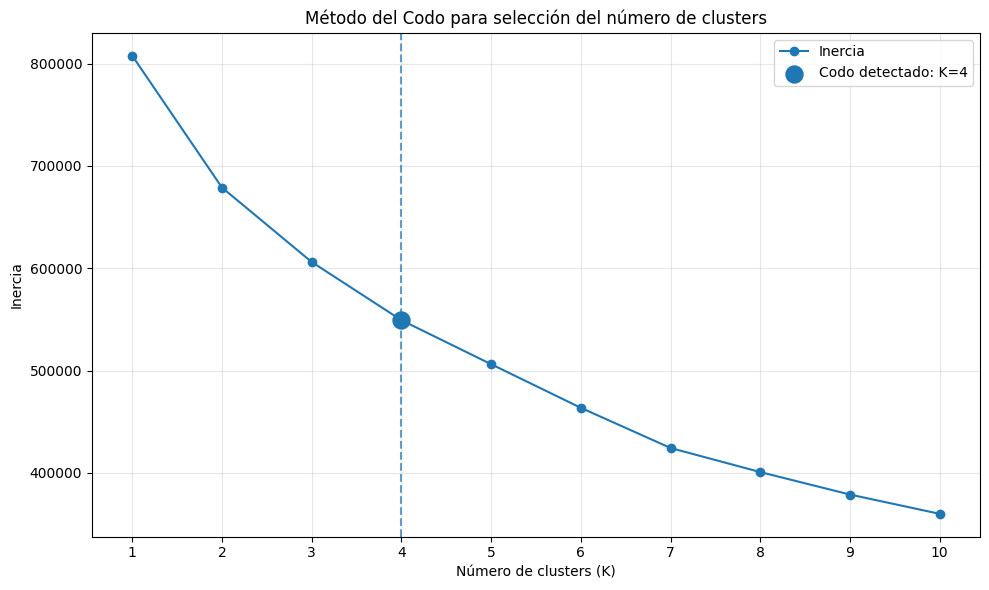

K sugerido mediante Elbow: 4


In [10]:
# =============================================================================
# VISUALIZACIÓN DEL MÉTODO ELBOW
# =============================================================================

"""
Visualización del Método del Codo (Elbow Method).

¿QUÉ HACE ESTE CÓDIGO?

Este código grafica la relación entre el número de clusters K y la inercia
obtenida por K-Means.

El procedimiento realiza los siguientes pasos:

1. Dibuja la curva completa de inercia para los distintos valores de K
   evaluados previamente.

2. Identifica el valor de K almacenado en `K_ELBOW`, obtenido mediante el
   criterio geométrico de detección automática del codo.

3. Busca la inercia correspondiente a ese valor de K.

4. Resalta visualmente el punto de codo mediante un marcador de mayor tamaño.

5. Agrega una línea vertical sobre el valor seleccionado para facilitar su
   identificación en el gráfico.

6. Muestra finalmente el valor de K sugerido por el Método del Codo.

¿CÓMO SE INTERPRETA EL GRÁFICO?

La inercia disminuye a medida que aumenta el número de clusters, ya que al
crear más grupos las observaciones pueden quedar más cerca de sus centroides.

Sin embargo, después de cierto punto, agregar nuevos clusters produce
reducciones cada vez menores en la inercia.

Ese cambio en la pendiente de la curva corresponde al llamado "codo".

El valor marcado en el gráfico representa la cantidad de clusters donde se
estima que comienza esa disminución de beneficios.

IMPORTANTE:

El punto resaltado no se obtiene únicamente mediante inspección visual.

Corresponde al valor calculado previamente mediante el criterio geométrico,
que identifica el punto de la curva con mayor distancia respecto de una línea
de referencia entre el primer y último valor evaluado.

El resultado debe interpretarse junto con otras métricas, como Silhouette
Score, y con la interpretabilidad de los segmentos obtenidos.
"""


plt.figure(
    figsize=(10, 6)
)


# Curva completa
plt.plot(
    df_evaluacion_k['k'],
    df_evaluacion_k['inercia'],
    marker='o',
    label='Inercia'
)


# Punto de codo
inercia_elbow = (
    df_evaluacion_k
    .loc[
        df_evaluacion_k['k'] == K_ELBOW,
        'inercia'
    ]
    .iloc[0]
)


plt.scatter(
    K_ELBOW,
    inercia_elbow,
    s=150,
    zorder=5,
    label=f'Codo detectado: K={K_ELBOW}'
)


# Línea vertical
plt.axvline(
    x=K_ELBOW,
    linestyle='--',
    alpha=0.7
)


plt.xticks(
    df_evaluacion_k['k']
)

plt.xlabel(
    'Número de clusters (K)'
)

plt.ylabel(
    'Inercia'
)

plt.title(
    'Método del Codo para selección del número de clusters'
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


print("=" * 75)

print(
    f"K sugerido mediante Elbow: "
    f"{K_ELBOW}"
)

print("=" * 75)

El Método del Codo identifica **K = 4** como una cantidad adecuada de clusters. A partir de este punto, el aumento en el número de grupos continúa reduciendo la inercia, pero con mejoras progresivamente menores. Por esta razón, se selecciona **K = 4** como solución principal para la segmentación, al ofrecer un equilibrio entre compactación e interpretabilidad.

## Silhouette Score

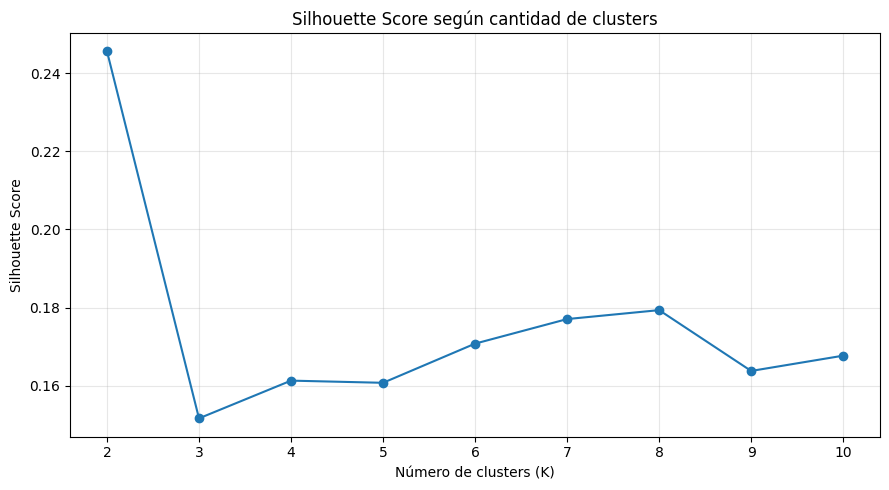

MEJOR RESULTADO SEGÚN SILHOUETTE

K = 2
Silhouette = 0.2456

Silhouette se utiliza como criterio complementario y no reemplaza la selección mediante Elbow.


In [11]:
# =============================================================================
# SILHOUETTE SCORE
# =============================================================================

"""
Evaluación del Silhouette Score para distintos valores de K.

¿QUÉ HACE ESTE CÓDIGO?

Este código analiza los valores de Silhouette obtenidos previamente para
cada cantidad de clusters evaluada.

El procedimiento realiza los siguientes pasos:

1. Elimina el caso K=1, ya que Silhouette no puede calcularse cuando existe
   un único cluster.

2. Grafica el Silhouette Score obtenido para cada valor de K >= 2.

3. Compara los resultados y busca el valor de K que presenta el mayor
   Silhouette Score.

4. Guarda ese valor en la variable `k_mejor_silhouette` y también conserva
   el puntaje correspondiente en `silhouette_mejor`.

¿QUÉ MIDE SILHOUETTE?

Silhouette evalúa qué tan bien se encuentran agrupadas las observaciones.

Considera dos aspectos al mismo tiempo:

- COHESIÓN:
  Qué tan cerca se encuentra una observación de las demás observaciones
  pertenecientes a su mismo cluster.

- SEPARACIÓN:
  Qué tan lejos se encuentra esa observación de los clusters vecinos.

En términos generales:

    valores cercanos a 1
        -> clusters compactos y bien separados.

    valores cercanos a 0
        -> existe mayor superposición entre los clusters.

    valores negativos
        -> algunas observaciones podrían estar más cerca de otro cluster
           que del cluster al que fueron asignadas.

¿CÓMO SE INTERPRETA EL RESULTADO?

El valor de K que obtiene el mayor Silhouette Score representa la solución
con mejor combinación de cohesión interna y separación entre grupos según
esta métrica.

Sin embargo, no necesariamente debe utilizarse automáticamente como el
número final de clusters.

IMPORTANTE:

En este análisis, Silhouette se utiliza como criterio complementario al
Método del Codo.

La selección final de K debe considerar conjuntamente:

- la reducción de la inercia;
- el punto de codo;
- el Silhouette Score;
- el tamaño de los clusters;
- y la interpretabilidad de los segmentos obtenidos.
"""


df_silhouette = (
    df_evaluacion_k
    .dropna(
        subset=['silhouette']
    )
    .copy()
)


plt.figure(
    figsize=(9, 5)
)


plt.plot(
    df_silhouette['k'],
    df_silhouette['silhouette'],
    marker='o'
)


plt.xticks(
    df_silhouette['k']
)

plt.xlabel(
    'Número de clusters (K)'
)

plt.ylabel(
    'Silhouette Score'
)

plt.title(
    'Silhouette Score según cantidad de clusters'
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# =============================================================================
# MEJOR SILHOUETTE
# =============================================================================

fila_mejor = (
    df_silhouette
    .loc[
        df_silhouette['silhouette'].idxmax()
    ]
)


k_mejor_silhouette = int(
    fila_mejor['k']
)

silhouette_mejor = float(
    fila_mejor['silhouette']
)


print("=" * 70)
print("MEJOR RESULTADO SEGÚN SILHOUETTE")
print("=" * 70)

print(
    f"\nK = {k_mejor_silhouette}"
)

print(
    f"Silhouette = {silhouette_mejor:.4f}"
)

print(
    "\nSilhouette se utiliza como criterio complementario "
    "y no reemplaza la selección mediante Elbow."
)

El mayor Silhouette Score se obtiene con **K=2 (~0,25)**, indicando que esta
configuración presenta la mayor separación global entre grupos. Sin embargo,
una solución de dos clusters genera una segmentación demasiado general para
el objetivo de identificar perfiles acústicos diferenciados.

Para **K=4**, seleccionado mediante el Método del Codo, el Silhouette Score
es cercano a **0,16**. Aunque presenta mayor superposición que K=2, permite
obtener cuatro segmentos con tamaños representativos y perfiles acústicos
claramente interpretables.

Por esta razón, Silhouette se utiliza como criterio complementario y se
mantiene **K=4** como solución final, priorizando el equilibrio entre
compactación, nivel de detalle e interpretabilidad de los segmentos.

## Selección del número final de clusters

El Método del Codo identificó **K = 4** como una cantidad adecuada de
clusters, al representar el punto a partir del cual aumentar el número
de grupos produce reducciones progresivamente menores en la inercia.

Como criterio complementario se calculó Silhouette Score. Su valor máximo
se obtuvo con K = 2; sin embargo, esta alternativa representa una
segmentación considerablemente más general.

Considerando que el objetivo del análisis es identificar perfiles acústicos
diferenciados y que el Método del Codo constituye el criterio principal de
selección, se continuará el análisis utilizando **K = 4**.

Posteriormente se evaluarán el tamaño, los centroides y la interpretabilidad
de los cuatro segmentos para comprobar su utilidad analítica.

In [12]:
# =============================================================================
# SELECCIÓN DEL NÚMERO FINAL DE CLUSTERS
# =============================================================================

"""
El número final de clusters se obtiene a partir del resultado del
Método del Codo.

En la evaluación realizada, el punto de codo fue identificado en K = 4.

Silhouette Score se utiliza como criterio complementario, pero no como
criterio exclusivo para seleccionar el número de segmentos.
"""

K_FINAL = K_ELBOW

print("=" * 70)
print("NÚMERO FINAL DE CLUSTERS")
print("=" * 70)

print(
    f"\nK seleccionado: {K_FINAL}"
)

print(
    "\nCriterio principal: Método del Codo (Elbow Method)."
)

NÚMERO FINAL DE CLUSTERS

K seleccionado: 4

Criterio principal: Método del Codo (Elbow Method).


## Entrenar K-Means definitivo

In [13]:
# =============================================================================
# ENTRENAMIENTO DEL MODELO K-MEANS DEFINITIVO
# =============================================================================

"""
Entrenamiento del modelo K-Means definitivo para segmentar las canciones.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque construye y entrena el modelo final de K-Means utilizando
las características acústicas que ya fueron preparadas previamente.

El procedimiento realiza los siguientes pasos:

1. Crea un modelo K-Means utilizando el número de clusters definido en
   `K_FINAL`.

2. Entrena el modelo con `X_cluster_scaled`, es decir, con las variables
   acústicas ya imputadas y estandarizadas.

3. Asigna cada canción a uno de los clusters encontrados.

4. Guarda esas asignaciones en la variable `clusters`.

5. Crea una copia del dataset original de clustering y agrega una nueva
   columna llamada `cluster`, que indica a qué segmento pertenece cada
   canción.

6. Muestra algunos resultados generales del modelo:
   - número de clusters utilizados;
   - inercia final;
   - cantidad de iteraciones necesarias para converger.

¿POR QUÉ SE UTILIZAN LOS DATOS ESTANDARIZADOS?

K-Means forma los grupos utilizando distancia euclidiana.

Como las variables originales poseen escalas diferentes, por ejemplo:

    duration_ms -> valores del orden de cientos de miles
    tempo       -> valores alrededor de cientos
    danceability -> valores entre 0 y 1

se utiliza `X_cluster_scaled` para evitar que una característica domine
la formación de los clusters únicamente por tener valores numéricamente
más grandes.

¿QUÉ SIGNIFICAN LOS PARÁMETROS DEL MODELO?

- `n_clusters=K_FINAL`:
  Define la cantidad de grupos que debe formar K-Means.

  En este análisis, K_FINAL corresponde al valor seleccionado previamente
  mediante el Método del Codo.

- `init='k-means++'`:
  Selecciona los centroides iniciales de manera estratégica.

  Esto reduce la posibilidad de comenzar con centroides poco adecuados y
  suele mejorar la estabilidad y velocidad de convergencia del algoritmo.

- `n_init=20`:
  Ejecuta K-Means 20 veces utilizando diferentes inicializaciones.

  De todas esas ejecuciones, conserva la solución que obtiene la menor
  inercia.

  Esto ayuda a reducir el riesgo de quedarse con una solución poco adecuada
  debido a una mala elección inicial de centroides.

- `max_iter=500`:
  Permite un máximo de 500 iteraciones por ejecución para que los centroides
  puedan estabilizarse.

- `random_state=42`:
  Fija una semilla aleatoria para que el proceso sea reproducible.

  Esto permite obtener los mismos resultados al volver a ejecutar el
  notebook bajo las mismas condiciones.

¿QUÉ HACE `fit_predict()`?

El método `fit_predict()` realiza dos tareas al mismo tiempo:

1. Entrena K-Means y calcula la posición de los centroides.
2. Asigna cada observación al cluster cuyo centroide se encuentra más cerca.

El resultado es una etiqueta numérica para cada canción, por ejemplo:

    0
    1
    2
    3

Estos números solamente identifican los segmentos y no representan un
orden de calidad o importancia.

¿QUÉ ES LA INERCIA FINAL?

La inercia representa la suma de las distancias cuadráticas entre cada
observación y el centroide de su cluster.

Una menor inercia significa que las canciones se encuentran, en promedio,
más cerca de los centroides de sus respectivos grupos.

Sin embargo, la inercia debe interpretarse considerando el número de
clusters utilizado y no como una medida absoluta de calidad.

¿QUÉ REPRESENTA `n_iter_`?

`n_iter_` indica cuántas iteraciones necesitó la mejor ejecución de K-Means
para alcanzar la convergencia.

La convergencia ocurre cuando los centroides dejan de cambiar de forma
significativa entre una iteración y la siguiente.

IMPORTANTE:

Los clusters obtenidos fueron construidos únicamente con las características
acústicas seleccionadas y estandarizadas.

Variables como `popularity` y `track_genre` no participaron en la formación
de los grupos y se utilizan posteriormente solo para caracterizar e
interpretar los segmentos encontrados.
"""


# =============================================================================
# MODELO
# =============================================================================

kmeans_final = KMeans(
    n_clusters=K_FINAL,
    init='k-means++',
    n_init=20,
    max_iter=500,
    random_state=42
)


# =============================================================================
# ENTRENAMIENTO Y ASIGNACIÓN
# =============================================================================

clusters = kmeans_final.fit_predict(
    X_cluster_scaled
)


# =============================================================================
# INCORPORAR RESULTADOS AL DATASET
# =============================================================================

df_resultados_cluster = (
    df_cluster.copy()
)

df_resultados_cluster[
    'cluster'
] = clusters


# =============================================================================
# RESULTADOS GENERALES
# =============================================================================

print("=" * 75)
print("MODELO K-MEANS ENTRENADO")
print("=" * 75)

print(
    f"\nNúmero de clusters : "
    f"{K_FINAL}"
)

print(
    f"Inercia final      : "
    f"{kmeans_final.inertia_:,.2f}"
)

print(
    f"Iteraciones        : "
    f"{kmeans_final.n_iter_}"
)

MODELO K-MEANS ENTRENADO

Número de clusters : 4
Inercia final      : 549,243.78
Iteraciones        : 16


El modelo final fue entrenado utilizando **4 clusters**, cantidad seleccionada previamente mediante el Método del Codo.

La **inercia final fue de 549.243,78**, valor que representa la suma de las distancias cuadráticas entre cada canción y el centroide de su grupo. Este resultado es coherente con el valor observado para K=4 durante la evaluación del método Elbow.

Además, el algoritmo necesitó **16 iteraciones para converger**, lo que indica que los centroides lograron estabilizarse antes de alcanzar el máximo de 500 iteraciones configurado.

En términos generales, el modelo logró construir correctamente los cuatro segmentos definidos y alcanzó una solución estable para continuar con su caracterización e interpretación.

## Revisar tamaños

In [14]:
# =============================================================================
# DISTRIBUCIÓN DE OBSERVACIONES POR CLUSTER
# =============================================================================

"""
Análisis de la distribución de canciones entre los clusters obtenidos.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque analiza cuántas canciones fueron asignadas a cada uno de los
clusters generados por K-Means y qué porcentaje representan respecto del
total del dataset.

El procedimiento realiza los siguientes pasos:

1. Cuenta cuántas canciones pertenecen a cada cluster utilizando
   `value_counts()`.

2. Ordena los resultados según el identificador del cluster para facilitar
   su lectura.

3. Calcula qué porcentaje del total de canciones representa cada segmento.

4. Construye una tabla resumen que contiene:
   - cantidad de canciones;
   - porcentaje de participación de cada cluster.

5. Muestra finalmente la información en formato de tabla y también como
   texto descriptivo.

¿POR QUÉ ES IMPORTANTE ANALIZAR EL TAMAÑO DE LOS CLUSTERS?

Después de aplicar K-Means es necesario comprobar cómo quedaron distribuidas
las observaciones.

Este análisis permite detectar situaciones como:

- clusters extremadamente pequeños;
- grupos que concentran casi todo el dataset;
- segmentos con tamaños suficientemente representativos.

Un cluster pequeño no significa necesariamente que el modelo sea incorrecto.

Puede corresponder a un perfil musical minoritario pero real. Sin embargo,
si un grupo contiene muy pocas observaciones, debe revisarse posteriormente
para determinar si representa un segmento legítimo o si está siendo generado
principalmente por observaciones extremas.

¿QUÉ SIGNIFICA EL PORCENTAJE?

El porcentaje indica qué proporción del catálogo analizado pertenece a cada
segmento.

Por ejemplo:

    Cluster 0 = 15%

significa que aproximadamente el 15% de las canciones fue asignado a ese
perfil acústico.

IMPORTANTE:

El tamaño de los clusters no se utiliza por sí solo para determinar la
calidad de la segmentación.

Debe analizarse en conjunto con:

- los centroides;
- las características acústicas de cada grupo;
- la presencia de observaciones extremas;
- y la interpretabilidad de los segmentos.

El objetivo de esta etapa es verificar que la solución obtenida sea
razonable y útil para continuar con la caracterización de cada cluster.
"""


# =============================================================================
# TABLA
# =============================================================================

distribucion_clusters = (
    df_resultados_cluster[
        'cluster'
    ]
    .value_counts()
    .sort_index()
)


porcentaje_clusters = (
    df_resultados_cluster[
        'cluster'
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)


resumen_clusters = pd.DataFrame(
    {
        'cantidad_canciones': distribucion_clusters,
        'porcentaje': porcentaje_clusters
    }
)


resumen_clusters.index.name = 'cluster'


# =============================================================================
# RESULTADOS
# =============================================================================

print("=" * 75)
print("DISTRIBUCIÓN DE LOS CLUSTERS")
print("=" * 75)

display(
    resumen_clusters.round(2)
)


print("\nDetalle:")


for cluster_id in resumen_clusters.index:

    print(
        f"Cluster {cluster_id}: "
        f"{int(resumen_clusters.loc[cluster_id, 'cantidad_canciones']):,} "
        f"canciones "
        f"({resumen_clusters.loc[cluster_id, 'porcentaje']:.2f}%)"
    )

DISTRIBUCIÓN DE LOS CLUSTERS


,cantidad_canciones,porcentaje
cluster,,
0,13870,15.46
1,7277,8.11
2,29505,32.88
3,39089,43.56



Detalle:
Cluster 0: 13,870 canciones (15.46%)
Cluster 1: 7,277 canciones (8.11%)
Cluster 2: 29,505 canciones (32.88%)
Cluster 3: 39,089 canciones (43.56%)


La segmentación obtenida distribuye las 89.741 canciones en cuatro grupos con tamaños diferenciados pero suficientemente representativos. El Cluster 3 concentra la mayor proporción del catálogo con un **43,56%**, seguido del Cluster 2 con un **32,88%**, mientras que los Clusters 0 y 1 representan un **15,46%** y **8,11%**, respectivamente.

No se observan clusters extremadamente pequeños ni grupos residuales formados por unas pocas observaciones. Incluso el segmento de menor tamaño contiene más de 7.000 canciones, por lo que todos los clusters poseen una cantidad suficiente de registros para ser analizados e interpretados.


Desde el punto de vista de la distribución, la solución obtenida puede considerarse **razonable y estable**, ya que K-Means no generó microclusters ni concentró prácticamente todas las observaciones en un único grupo.

Sin embargo, que los tamaños sean adecuados no demuestra por sí solo que la segmentación sea de alta calidad. La calidad final debe evaluarse también mediante el Silhouette Score, los centroides y la interpretabilidad de los perfiles.

En este caso, la distribución de tamaños respalda la solución de **K=4**, ya que los cuatro segmentos poseen suficiente representación como para ser considerados perfiles relevantes dentro del catálogo.

# centroides estandarizados

In [15]:
# =============================================================================
# ANÁLISIS DE LOS CENTROIDES ESTANDARIZADOS
# =============================================================================

"""
Análisis de los centroides estandarizados obtenidos por K-Means.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque extrae los centroides calculados por el modelo K-Means y los
organiza en una tabla para facilitar la interpretación de cada segmento.

El procedimiento realiza los siguientes pasos:

1. Obtiene los centroides almacenados en `kmeans_final.cluster_centers_`.

2. Asigna a cada columna el nombre de la característica acústica
   correspondiente.

3. Asigna a cada fila el nombre del cluster al que pertenece el centroide.

4. Muestra finalmente una tabla con los valores redondeados para facilitar
   su lectura.

¿QUÉ ES UN CENTROIDE?

Un centroide representa el punto central de un cluster.

Puede interpretarse como el perfil promedio que utiliza K-Means para
representar a las canciones pertenecientes a ese segmento dentro del
espacio de características utilizado por el modelo.

¿POR QUÉ LOS CENTROIDES ESTÁN ESTANDARIZADOS?

Antes de entrenar K-Means, las características acústicas fueron transformadas
mediante `StandardScaler`.

Por esta razón, los valores de los centroides no están expresados directamente
en sus unidades originales, sino en desviaciones estándar respecto del
promedio general de cada característica.

La interpretación general es:

    valor cercano a 0
        -> el cluster presenta un comportamiento similar al promedio general.

    valor positivo
        -> la característica se encuentra por encima del promedio general.

    valor negativo
        -> la característica se encuentra por debajo del promedio general.

Por ejemplo:

    acousticness = +1.20

indica que el centroide del cluster se encuentra aproximadamente
1.20 desviaciones estándar por encima del promedio general de
`acousticness`.

En cambio:

    danceability = -0.80

indica que el cluster presenta una `danceability` relativamente menor
que el promedio del conjunto de canciones.

¿PARA QUÉ SIRVE ESTE ANÁLISIS?

Comparar los centroides permite identificar qué características acústicas
diferencian principalmente a cada segmento.

Esto facilita posteriormente:

- caracterizar los clusters;
- identificar sus rasgos relativamente altos y bajos;
- construir mapas de calor;
- asignar una interpretación de negocio a cada segmento.

IMPORTANTE:

Los valores positivos no representan características "buenas" y los valores
negativos no representan características "malas".

Solo indican si una característica se encuentra por encima o por debajo
del promedio general del dataset.

Además, estos valores deben distinguirse de los centroides en unidades
originales, que posteriormente pueden obtenerse aplicando la transformación
inversa de `StandardScaler`.
"""


# =============================================================================
# CREAR DATAFRAME DE CENTROIDES
# =============================================================================

centroides_estandarizados = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=features_cluster
)


# Asignar nombres de cluster al índice
centroides_estandarizados.index = [
    f'Cluster {cluster_id}'
    for cluster_id in range(K_FINAL)
]


# =============================================================================
# MOSTRAR RESULTADOS
# =============================================================================

print("=" * 85)
print("CENTROIDES ESTANDARIZADOS DE LOS CLUSTERS")
print("=" * 85)

display(
    centroides_estandarizados.round(3)
)

CENTROIDES ESTANDARIZADOS DE LOS CLUSTERS


,duration_ms,danceability,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Cluster 0,-0.134,-0.885,-1.599,-0.325,1.453,0.898,-0.275,-0.871,-0.592
Cluster 1,0.031,-0.174,0.161,1.105,0.119,-0.354,2.617,0.097,-0.036
Cluster 2,0.312,-0.413,0.360,-0.122,-0.606,0.174,-0.167,-0.608,0.437
Cluster 3,-0.193,0.657,0.264,0.002,-0.080,-0.383,-0.263,0.748,-0.113


Los centroides permiten identificar qué características diferencian a cada segmento respecto del promedio general del dataset.

- **Cluster 0:** destaca por una `acousticness` muy alta (+1.453) y mayor `instrumentalness` (+0.898). En cambio, presenta menor `danceability` (-0.885), `valence` (-0.871) y especialmente menor `loudness` (-1.599). Esto representa un perfil más acústico, instrumental y menos intenso.

- **Cluster 1:** se diferencia principalmente por una `liveness` muy elevada (+2.617) y mayor `speechiness` (+1.105). El resto de las variables se mantiene relativamente cerca del promedio. Corresponde a un perfil más asociado a interpretaciones en vivo y mayor presencia hablada.

- **Cluster 2:** presenta mayor `tempo` (+0.437), mayor `loudness` (+0.360) y canciones ligeramente más largas (+0.312). Al mismo tiempo, posee menor `acousticness` (-0.606) y `valence` (-0.608). Esto sugiere un perfil más rápido, intenso y poco acústico.

- **Cluster 3:** destaca principalmente por una mayor `valence` (+0.748) y `danceability` (+0.657), junto con menor `instrumentalness` (-0.383). Esto representa un perfil más bailable, positivo y con mayor presencia vocal.

En conjunto, los centroides muestran que los cuatro clusters poseen perfiles acústicos diferenciados e interpretables, lo que respalda la utilidad de la segmentación obtenida.

## Heatmap

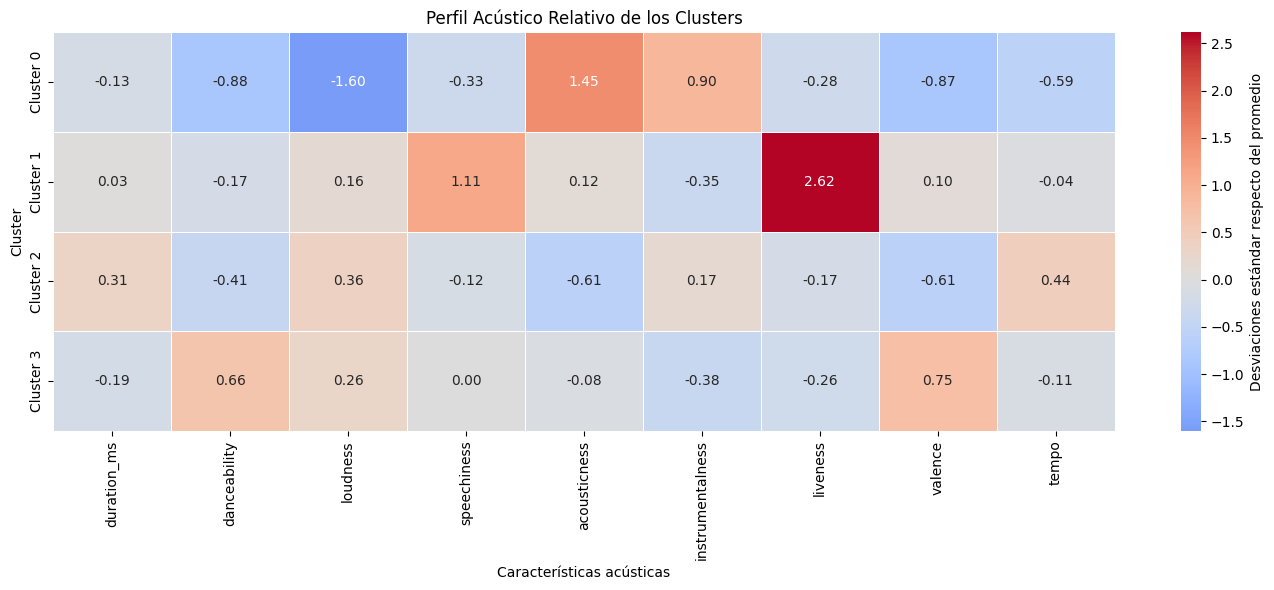

In [16]:
# =============================================================================
# MAPA DE CALOR DEL PERFIL DE LOS CLUSTERS
# =============================================================================

"""
Visualización del perfil acústico relativo de los clusters mediante un mapa
de calor.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque representa gráficamente los centroides estandarizados obtenidos
por K-Means.

El procedimiento realiza los siguientes pasos:

1. Utiliza la tabla `centroides_estandarizados`, donde cada fila representa
   un cluster y cada columna una característica acústica.

2. Construye un mapa de calor en el que el color de cada celda representa
   qué tan por encima o por debajo del promedio general se encuentra una
   característica dentro de cada cluster.

3. Muestra dentro de cada celda el valor estandarizado correspondiente,
   redondeado a dos decimales.

4. Centra la escala de colores en 0 para diferenciar con claridad los valores
   superiores e inferiores al promedio.

¿CÓMO SE INTERPRETA EL MAPA?

Como los centroides fueron calculados sobre datos transformados mediante
`StandardScaler`, los valores se interpretan en desviaciones estándar
respecto del promedio general del dataset.

La interpretación es:

    valor cercano a 0
        -> característica similar al promedio general.

    valor positivo
        -> característica por encima del promedio general.

    valor negativo
        -> característica por debajo del promedio general.

Además, mientras mayor sea la magnitud del valor, mayor es la diferencia
respecto del comportamiento promedio.

Por ejemplo:

    acousticness = +1.45

indica que ese cluster presenta una acousticness considerablemente superior
al promedio general.

En cambio:

    loudness = -1.60

indica que el cluster presenta un nivel de loudness considerablemente menor
que el promedio.

¿PARA QUÉ SIRVE ESTE GRÁFICO?

El mapa de calor permite comparar rápidamente los perfiles de los clusters
y detectar cuáles son las características que más diferencian a cada
segmento.

Esto facilita:

- identificar rasgos dominantes;
- detectar características relativamente bajas;
- comparar los clusters entre sí;
- caracterizar los segmentos;
- y traducir los resultados del modelo a una interpretación de negocio.

IMPORTANTE:

Los colores positivos y negativos no representan características buenas o
malas.

Solo indican si una variable se encuentra por encima o por debajo del
promedio general del conjunto de canciones.

La interpretación final debe considerar el conjunto de características de
cada cluster y no una variable de forma aislada.
"""


plt.figure(
    figsize=(14, 6)
)


sns.heatmap(
    centroides_estandarizados,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    cbar_kws={
        'label': 'Desviaciones estándar respecto del promedio'
    }
)


plt.title(
    'Perfil Acústico Relativo de los Clusters'
)

plt.xlabel(
    'Características acústicas'
)

plt.ylabel(
    'Cluster'
)

plt.tight_layout()

plt.show()

El mapa de calor permite identificar con claridad las características que más diferencian a cada segmento respecto del promedio general del dataset.

- **Cluster 0:** presenta un perfil fuertemente acústico e instrumental, con `acousticness` (+1.45) e `instrumentalness` (+0.90) por encima del promedio. En contraste, posee menor `loudness` (-1.60), `danceability` (-0.88) y `valence` (-0.87). Corresponde a un perfil más suave, acústico y menos orientado al baile.

- **Cluster 1:** destaca principalmente por una `liveness` muy elevada (+2.62) y mayor `speechiness` (+1.11). Esto indica un segmento con fuerte presencia de características asociadas a interpretaciones en vivo o contenido hablado.

- **Cluster 2:** presenta mayor `tempo` (+0.44), `loudness` (+0.36) y duración (+0.31), mientras que muestra menor `acousticness` (-0.61) y `valence` (-0.61). Esto representa un perfil más rápido, intenso y menos acústico.

- **Cluster 3:** se caracteriza por una mayor `valence` (+0.75) y `danceability` (+0.66), junto con menor `instrumentalness` (-0.38). Corresponde al perfil más bailable y positivo de los cuatro segmentos.

En conjunto, el mapa confirma que los cuatro clusters poseen perfiles acústicos claramente diferenciados, lo que facilita su interpretación y posterior utilización en estrategias de segmentación y recomendación.

## Distribución de valores extremos por cluster

In [17]:
# =============================================================================
# DISTRIBUCIÓN DE OBSERVACIONES EXTREMAS POR CLUSTER
# =============================================================================

"""
Diagnóstico de la presencia de observaciones extremas dentro de cada cluster.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque analiza si los clusters obtenidos por K-Means contienen una
proporción importante de observaciones con valores acústicos muy alejados
del promedio general.

El procedimiento realiza los siguientes pasos:

1. Toma una copia del dataset estandarizado utilizado por K-Means.

2. Agrega a cada observación la etiqueta del cluster al que fue asignada.

3. Revisa todas las características acústicas utilizadas en la segmentación.

4. Marca una canción como "observación extrema" cuando al menos una de sus
   características presenta un valor estandarizado mayor a 3 o menor a -3.

5. Agrupa los resultados por cluster.

6. Calcula para cada segmento:
   - cantidad total de canciones;
   - cantidad de observaciones extremas;
   - porcentaje de observaciones extremas.

¿QUÉ SIGNIFICA |z| > 3?

Las variables fueron transformadas previamente mediante `StandardScaler`.

Por esta razón, cada valor puede interpretarse en términos de desviaciones
estándar respecto del promedio general.

El criterio:

    |z| > 3

significa que una característica se encuentra a más de 3 desviaciones
estándar del promedio.

Por ejemplo:

    z = +3.5
        -> valor considerablemente superior al promedio.

    z = -4.0
        -> valor considerablemente inferior al promedio.

¿POR QUÉ SE REALIZA ESTE ANÁLISIS?

K-Means utiliza distancia euclidiana y, por lo tanto, puede verse influido
por observaciones muy alejadas del comportamiento general.

Como durante el EDA se determinó que los valores extremos corresponden a
casos plausibles del dominio musical, estos no fueron eliminados ni
winsorizados.

Este análisis permite comprobar si alguno de los clusters está compuesto
en gran medida por este tipo de observaciones.

¿CÓMO SE INTERPRETA EL RESULTADO?

Si un cluster presenta un porcentaje de observaciones extremas similar al
resto, no existe una señal evidente de que el segmento esté siendo definido
principalmente por valores extremos.

En cambio, si un cluster concentra una proporción considerablemente mayor,
debe analizarse con mayor atención para determinar si:

- representa un perfil musical minoritario real; o
- está siendo fuertemente influido por características extremas.

IMPORTANTE:

Una observación clasificada como extrema NO se considera automáticamente
incorrecta ni un error del dataset.

El criterio |z| > 3 se utiliza únicamente como herramienta de diagnóstico.

La interpretación final debe realizarse junto con los centroides, el mapa
de calor, el tamaño de los clusters y el conocimiento obtenido durante el
análisis exploratorio de datos.
"""


# =============================================================================
# 1. DATAFRAME ESTANDARIZADO
# =============================================================================

df_scaled_diagnostico = X_cluster_scaled_df.copy()

df_scaled_diagnostico[
    'cluster'
] = clusters


# =============================================================================
# 2. IDENTIFICAR OBSERVACIONES CON AL MENOS UN |Z| > 3
# =============================================================================

columnas_acusticas = features_cluster


df_scaled_diagnostico[
    'observacion_extrema'
] = (
    df_scaled_diagnostico[
        columnas_acusticas
    ]
    .abs()
    .gt(3)
    .any(axis=1)
)


# =============================================================================
# 3. RESUMEN POR CLUSTER
# =============================================================================

resumen_extremos = (
    df_scaled_diagnostico
    .groupby('cluster')
    ['observacion_extrema']
    .agg(
        total='count',
        observaciones_extremas='sum'
    )
)


resumen_extremos[
    'porcentaje_extremos'
] = (
    resumen_extremos[
        'observaciones_extremas'
    ]
    /
    resumen_extremos[
        'total'
    ]
    * 100
)


# =============================================================================
# 4. RESULTADOS
# =============================================================================

print("=" * 85)
print("PRESENCIA DE OBSERVACIONES EXTREMAS POR CLUSTER")
print("=" * 85)

display(
    resumen_extremos.round(2)
)

PRESENCIA DE OBSERVACIONES EXTREMAS POR CLUSTER


,total,observaciones_extremas,porcentaje_extremos
cluster,,,
0,13870,2324,16.76
1,7277,3421,47.01
2,29505,508,1.72
3,39089,428,1.09


La distribución de valores extremos no es homogénea entre los segmentos.

El **Cluster 1** concentra la mayor proporción de observaciones extremas, con un **47,01%**, seguido por el **Cluster 0** con un **16,76%**. En cambio, los Clusters 2 y 3 presentan porcentajes muy bajos, de **1,72%** y **1,09%**, respectivamente.

Esto indica que el Cluster 1 está fuertemente asociado a canciones con características acústicas alejadas del promedio, especialmente coherente con sus altos valores de `liveness` y `speechiness`.

Sin embargo, estas observaciones no se consideran errores, ya que durante el EDA se determinó que los valores extremos forman parte de la realidad del dominio musical. Por ello, el Cluster 1 puede interpretarse como un segmento particular o de nicho, más que como un resultado incorrecto del modelo.

En general, los resultados muestran que los valores extremos influyen principalmente en un segmento específico y no dominan la segmentación completa.

## PCA completo

In [18]:
# =============================================================================
# PCA COMPLETO
# =============================================================================

"""
Aplicación de Análisis de Componentes Principales (PCA) sobre las
características acústicas estandarizadas.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque aplica PCA sobre `X_cluster_scaled` con el objetivo de estudiar
cómo se distribuye la información contenida en las variables acústicas.

El procedimiento realiza los siguientes pasos:

1. Crea un modelo PCA sin limitar inicialmente la cantidad de componentes.

2. Ajusta PCA utilizando `X_cluster_scaled`, es decir, el mismo conjunto de
   características estandarizadas que fue utilizado previamente por K-Means.

3. Transforma las variables originales en nuevos componentes principales.

4. Calcula cuánto porcentaje de la varianza total explica cada componente.

5. Calcula también la varianza explicada acumulada, que permite saber cuánta
   información se conserva al utilizar varios componentes en conjunto.

6. Organiza estos resultados en una tabla para facilitar su análisis.

¿QUÉ ES PCA?

PCA es una técnica de reducción de dimensionalidad.

Su objetivo es transformar las variables originales en nuevas variables
llamadas componentes principales.

Estos componentes se construyen como combinaciones de las características
originales y buscan concentrar la mayor cantidad posible de variabilidad
del dataset.

El primer componente principal explica la mayor cantidad posible de varianza.

El segundo componente explica la mayor cantidad posible de la varianza
restante, y así sucesivamente.

¿QUÉ ES LA VARIANZA EXPLICADA?

La varianza explicada indica qué proporción de la información del dataset
queda representada por cada componente principal.

Por ejemplo:

    PC1 = 25%

significa que el primer componente representa aproximadamente el 25% de la
variabilidad total presente en las características acústicas.

¿QUÉ ES LA VARIANZA ACUMULADA?

La varianza acumulada suma progresivamente la información explicada por los
componentes.

Por ejemplo:

    PC1 = 25%
    PC2 = 15%

implica que PC1 y PC2 juntos representan aproximadamente el 40% de la
varianza total.

Esto permite determinar cuántos componentes serían necesarios para conservar,
por ejemplo:

- 80% de la información;
- 90% de la información;
- 95% de la información.

¿POR QUÉ NO SE LIMITAN LOS COMPONENTES DESDE EL INICIO?

En esta etapa se utilizan todos los componentes posibles para poder estudiar
cómo se distribuye la varianza antes de decidir cuántos componentes podrían
ser suficientes para representar el dataset.

Esto evita seleccionar arbitrariamente una cantidad de dimensiones.

¿PARA QUÉ SE UTILIZA PCA EN ESTE ANÁLISIS?

PCA se utiliza principalmente para:

- estudiar la estructura dimensional del dataset;
- analizar la varianza explicada;
- identificar cuántos componentes concentran la mayor parte de la información;
- y posteriormente visualizar los clusters en un espacio reducido.

IMPORTANTE:

PCA NO se utiliza aquí para volver a crear los clusters.

Los clusters ya fueron obtenidos mediante K-Means utilizando las
características acústicas estandarizadas completas.

En esta etapa, PCA se utiliza como herramienta de análisis y visualización
posterior de la segmentación.
"""


# =============================================================================
# 1. CREAR PCA
# =============================================================================

pca_completo = PCA()


# =============================================================================
# 2. AJUSTAR Y TRANSFORMAR
# =============================================================================

X_pca_completo = pca_completo.fit_transform(
    X_cluster_scaled
)


# =============================================================================
# 3. VARIANZA EXPLICADA
# =============================================================================

varianza_explicada = (
    pca_completo
    .explained_variance_ratio_
)


varianza_acumulada = np.cumsum(
    varianza_explicada
)


# =============================================================================
# 4. TABLA DE RESULTADOS
# =============================================================================

df_varianza_pca = pd.DataFrame(
    {
        'componente': np.arange(
            1,
            len(varianza_explicada) + 1
        ),

        'varianza_explicada': varianza_explicada,

        'porcentaje_varianza': (
            varianza_explicada * 100
        ),

        'varianza_acumulada': varianza_acumulada,

        'porcentaje_acumulado': (
            varianza_acumulada * 100
        )
    }
)


# =============================================================================
# 5. MOSTRAR
# =============================================================================

print("=" * 85)
print("VARIANZA EXPLICADA POR PCA")
print("=" * 85)

display(
    df_varianza_pca.round(4)
)

VARIANZA EXPLICADA POR PCA


,componente,varianza_explicada,porcentaje_varianza,varianza_acumulada,porcentaje_acumulado
0,1,0.2547,25.4692,0.2547,25.4692
1,2,0.1519,15.1863,0.4066,40.6555
2,3,0.1392,13.9205,0.5458,54.5760
3,4,0.1068,10.6812,0.6526,65.2572
4,5,0.0969,9.6914,0.7495,74.9485
5,6,0.0881,8.8120,0.8376,83.7605
6,7,0.0805,8.0463,0.9181,91.8068
7,8,0.0470,4.7024,0.9651,96.5092
8,9,0.0349,3.4908,1.0000,100.0000


El análisis PCA muestra que la información del dataset se encuentra distribuida entre varios componentes y no concentrada únicamente en los primeros dos.

- El **Componente Principal 1** explica aproximadamente un **25,47%** de la varianza.
- El **Componente Principal 2** explica un **15,19%** adicional.
- En conjunto, los dos primeros componentes representan aproximadamente un **40,66%** de la variabilidad total.

Para conservar una mayor proporción de la información se requieren más componentes:

- **6 componentes** explican aproximadamente el **83,76%** de la varianza.
- **7 componentes** alcanzan aproximadamente el **91,81%**.
- **8 componentes** permiten representar aproximadamente el **96,51%**.

Esto indica que la estructura acústica del dataset es multidimensional. Por esta razón, la representación mediante solo dos componentes principales es útil principalmente para **visualizar los clusters**, pero no representa toda la información utilizada originalmente por K-Means.

## Gráfico de varianza explicada acumulada

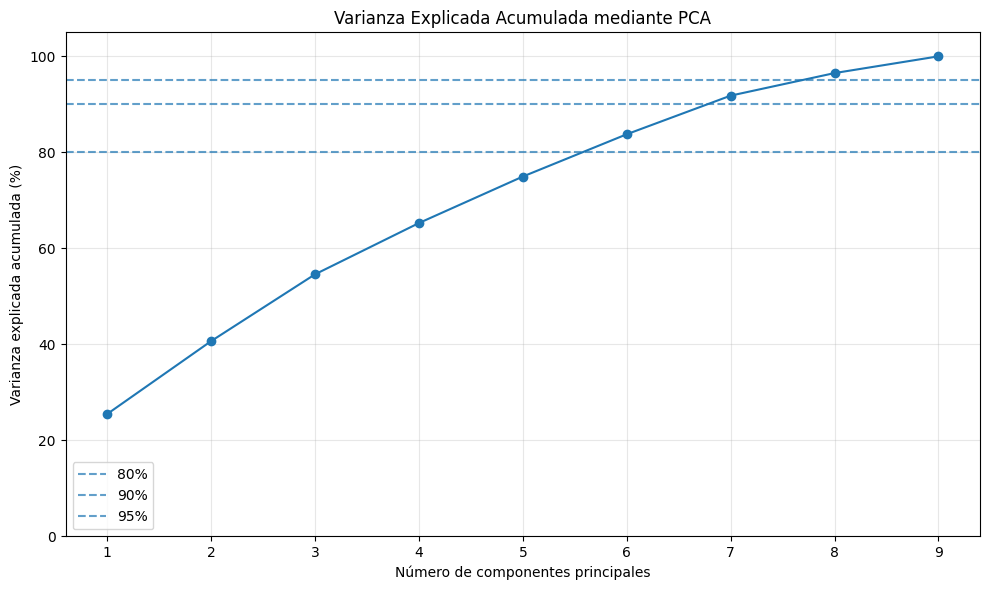

In [19]:
# =============================================================================
# VARIANZA EXPLICADA ACUMULADA
# =============================================================================

"""
Visualización de la varianza explicada acumulada mediante PCA.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque genera un gráfico que muestra cómo aumenta el porcentaje de
varianza representada a medida que se incorporan más componentes principales.

El procedimiento realiza los siguientes pasos:

1. Utiliza la tabla `df_varianza_pca`, que contiene el porcentaje de varianza
   acumulada para cada cantidad de componentes.

2. Grafica en el eje horizontal el número de componentes principales.

3. Grafica en el eje vertical el porcentaje de varianza explicada acumulada.

4. Agrega tres líneas horizontales de referencia en:

       80%
       90%
       95%

   Estas líneas permiten identificar visualmente cuántos componentes son
   necesarios para alcanzar distintos niveles de representación de la
   información original.

¿QUÉ ES LA VARIANZA EXPLICADA ACUMULADA?

La varianza explicada acumulada representa la suma de la información aportada
por los componentes principales considerados hasta un determinado punto.

Por ejemplo:

    PC1 explica 25%
    PC2 explica 15%

significa que los dos primeros componentes explican conjuntamente
aproximadamente el 40% de la variabilidad total del dataset.

A medida que se agregan componentes, la varianza acumulada aumenta hasta
alcanzar finalmente el 100%.

¿CÓMO SE INTERPRETA EL GRÁFICO?

El gráfico permite observar cuántos componentes se necesitan para conservar
una determinada proporción de la información.

Por ejemplo, si la curva supera el 80% al utilizar 6 componentes, significa
que esos 6 componentes permiten representar al menos el 80% de la
variabilidad original.

Las líneas de referencia facilitan identificar los componentes necesarios
para alcanzar:

- 80% de la varianza;
- 90% de la varianza;
- 95% de la varianza.

¿PARA QUÉ SIRVE ESTE ANÁLISIS?

Este gráfico ayuda a evaluar si es posible reducir la cantidad de dimensiones
del dataset sin perder una proporción importante de información.

También permite determinar si una representación en solo dos componentes
principales es suficiente para describir la estructura completa de los datos.

IMPORTANTE:

En este análisis PCA se utiliza principalmente como herramienta de estudio y
visualización.

Los clusters ya fueron creados previamente mediante K-Means utilizando las
9 características acústicas estandarizadas.

Por lo tanto, el gráfico no modifica la segmentación obtenida; únicamente
permite evaluar cuánta información sería conservada al representar el dataset
con una cantidad menor de componentes principales.
"""


plt.figure(
    figsize=(10, 6)
)


plt.plot(
    df_varianza_pca['componente'],
    df_varianza_pca['porcentaje_acumulado'],
    marker='o'
)


# Líneas de referencia
plt.axhline(
    y=80,
    linestyle='--',
    alpha=0.7,
    label='80%'
)

plt.axhline(
    y=90,
    linestyle='--',
    alpha=0.7,
    label='90%'
)

plt.axhline(
    y=95,
    linestyle='--',
    alpha=0.7,
    label='95%'
)


plt.xticks(
    df_varianza_pca['componente']
)

plt.ylim(
    0,
    105
)

plt.xlabel(
    'Número de componentes principales'
)

plt.ylabel(
    'Varianza explicada acumulada (%)'
)

plt.title(
    'Varianza Explicada Acumulada mediante PCA'
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

El gráfico muestra que la información del dataset se encuentra distribuida entre varios componentes principales y no se concentra únicamente en los primeros.

- Con **6 componentes** se supera aproximadamente el **80%** de la varianza explicada.
- Con **7 componentes** se supera aproximadamente el **90%**.
- Con **8 componentes** se supera aproximadamente el **95%**.

Esto indica que para conservar la mayor parte de la información original se necesitan varios componentes. Por lo tanto, una representación con solo **2 componentes principales** es útil principalmente para visualizar los clusters, pero no representa completamente toda la variabilidad utilizada originalmente por K-Means.

## ¿Qué variables construyen cada componente?

In [20]:
# =============================================================================
# PESOS DE LAS VARIABLES EN LOS COMPONENTES PRINCIPALES
# =============================================================================

"""
Análisis de los pesos o cargas de las variables dentro de los componentes
principales generados mediante PCA.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque permite identificar qué características acústicas tienen mayor
participación en la construcción de cada componente principal.

El procedimiento realiza los siguientes pasos:

1. Obtiene los coeficientes calculados por PCA mediante
   `pca_completo.components_`.

2. Transpone la matriz para que:
   - cada fila represente una característica acústica;
   - cada columna represente un componente principal.

3. Asigna los nombres originales de las variables a las filas.

4. Asigna nombres PC1, PC2, PC3, etc. a los componentes.

5. Organiza los resultados en una tabla para facilitar su interpretación.

¿QUÉ REPRESENTAN LOS PESOS?

Cada componente principal se construye como una combinación de las variables
originales.

Los pesos indican cuánto participa cada característica en esa combinación.

Por ejemplo, si dentro de PC1 aparecen valores como:

    acousticness     +0.60
    loudness         -0.55
    danceability     +0.10

significa que `acousticness` y `loudness` tienen una participación importante
en la construcción de PC1, mientras que `danceability` tiene una influencia
menor.

¿CÓMO SE INTERPRETAN LOS VALORES?

Lo más importante para medir la participación de una variable es la magnitud
absoluta del coeficiente.

En términos generales:

    valor cercano a 0
        -> poca participación en ese componente.

    valor positivo alto
        -> participación importante en dirección positiva.

    valor negativo alto en magnitud
        -> participación importante, pero en dirección opuesta.

Por ejemplo:

    +0.70

y

    -0.70

representan una participación similar en importancia.

La diferencia está en la dirección de la relación con el componente.

¿QUÉ SIGNIFICA EL SIGNO?

El signo permite conocer la dirección en la que una variable se relaciona
con el componente.

Si dos variables tienen signos iguales dentro de un componente, tienden a
aportar en la misma dirección.

Si presentan signos opuestos, contribuyen en direcciones contrarias dentro
de ese componente.

IMPORTANTE:
Un coeficiente negativo NO significa que la variable sea negativa o poco
importante.

Para evaluar importancia se debe observar principalmente el valor absoluto
del coeficiente.

¿PARA QUÉ SIRVE ESTE ANÁLISIS?

Analizar los pesos permite comprender qué representa cada componente
principal y darle una interpretación basada en las características acústicas
originales.

Esto resulta especialmente útil para:

- identificar qué variables dominan PC1, PC2, PC3, etc.;
- comprender qué información resume cada componente;
- interpretar posteriormente los gráficos PCA;
- y explicar por qué determinados clusters aparecen separados en el espacio
  de componentes principales.

IMPORTANTE:

Los componentes principales no corresponden directamente a una sola
característica acústica.

Cada componente representa una combinación de varias variables, por lo que
su interpretación debe realizarse considerando conjuntamente aquellas que
presentan los mayores pesos en valor absoluto.
"""


# =============================================================================
# CREAR TABLA
# =============================================================================

pesos_pca = pd.DataFrame(
    pca_completo.components_.T,
    index=features_cluster,
    columns=[
        f'PC{i}'
        for i in range(
            1,
            len(features_cluster) + 1
        )
    ]
)


print("=" * 85)
print("PESOS DE LAS VARIABLES EN LOS COMPONENTES")
print("=" * 85)

display(
    pesos_pca.round(3)
)

PESOS DE LAS VARIABLES EN LOS COMPONENTES


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
duration_ms,-0.073,-0.469,-0.030,0.674,-0.062,0.516,-0.212,-0.061,0.022
danceability,0.395,0.317,-0.284,0.395,0.267,-0.013,0.157,0.639,-0.051
loudness,0.533,-0.265,0.059,-0.031,-0.202,-0.207,-0.075,0.005,0.743
speechiness,0.109,0.210,0.582,0.257,0.546,-0.214,-0.389,-0.209,0.012
acousticness,-0.388,0.496,0.030,-0.111,0.002,0.460,-0.199,0.178,0.555
instrumentalness,-0.405,-0.190,-0.152,0.185,0.473,-0.227,0.559,-0.147,0.366
liveness,0.046,-0.014,0.725,0.041,-0.218,0.218,0.568,0.227,-0.036
valence,0.430,0.357,-0.165,0.038,0.066,0.387,0.313,-0.637,-0.006
tempo,0.201,-0.394,0.015,-0.522,0.557,0.430,-0.034,0.182,-0.041


Los pesos permiten identificar qué características tienen mayor influencia en la construcción de cada componente principal.

- **PC1** está definido principalmente por `loudness` (+0.533), `valence` (+0.430), `instrumentalness` (-0.405), `danceability` (+0.395) y `acousticness` (-0.388). Por lo tanto, este componente diferencia principalmente canciones más intensas, bailables y positivas frente a canciones más acústicas e instrumentales.

- **PC2** está asociado principalmente con mayor `acousticness` (+0.496) y menor `duration_ms` (-0.469) y `tempo` (-0.394). Este componente distingue canciones más acústicas de canciones más largas y rápidas.

- **PC3** está claramente dominado por `liveness` (+0.725) y `speechiness` (+0.582). Esto indica que representa principalmente características relacionadas con presencia en vivo y contenido hablado.

- **PC4** está influenciado principalmente por `duration_ms` (+0.674) y `tempo` (-0.522), por lo que diferencia canciones más largas de aquellas con mayor velocidad.

En general, los resultados muestran que cada componente resume una combinación diferente de características acústicas. Esto confirma que PCA no reemplaza las variables originales por una sola característica, sino que las combina para representar distintas dimensiones del comportamiento musical.

Los signos positivos y negativos indican la dirección de la relación con cada componente; la importancia de una variable se determina principalmente por la magnitud absoluta de su peso.

## Heatmap de componentes

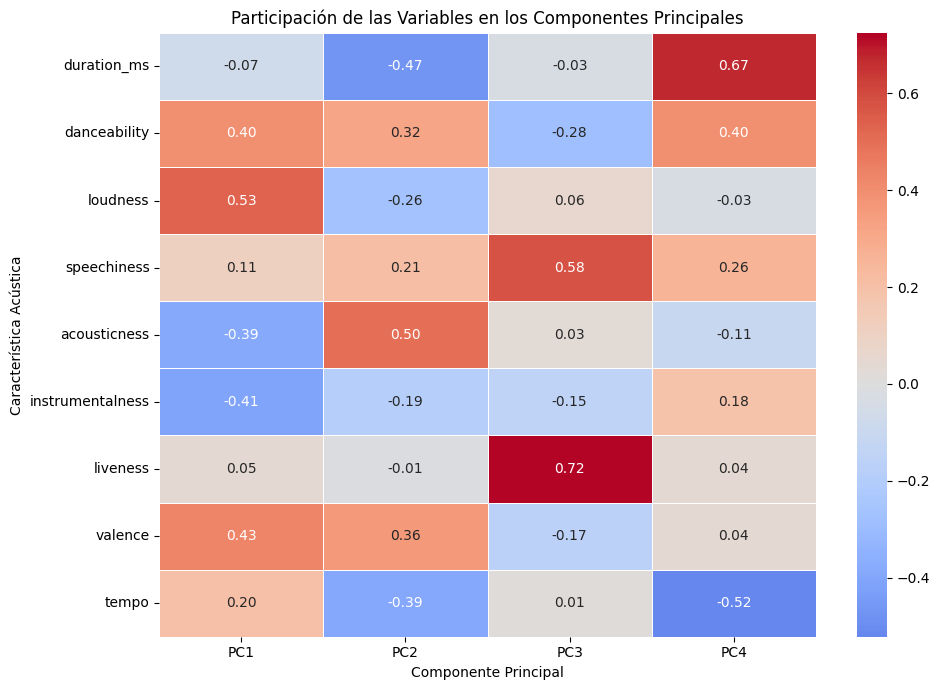

In [21]:
# =============================================================================
# HEATMAP DE LOS PRIMEROS COMPONENTES
# =============================================================================

"""
Visualización de la participación de las variables acústicas en los primeros
componentes principales mediante un mapa de calor.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque representa gráficamente los pesos calculados previamente por PCA
para facilitar la interpretación de los componentes principales.

El procedimiento realiza los siguientes pasos:

1. Define cuántos componentes principales se mostrarán en el gráfico.

2. Selecciona desde `pesos_pca` los primeros componentes principales.

3. Construye un mapa de calor donde:
   - cada fila representa una característica acústica;
   - cada columna representa un componente principal;
   - cada celda contiene el peso de esa variable dentro del componente.

4. Utiliza una escala de colores centrada en 0 para distinguir fácilmente
   los pesos positivos de los negativos.

5. Muestra dentro de cada celda el valor numérico del peso correspondiente.

¿CÓMO SE INTERPRETA EL MAPA?

La intensidad del color permite identificar qué variables tienen una mayor
participación en cada componente principal.

En términos generales:

    valor cercano a 0
        -> la variable tiene poca participación en ese componente.

    valor positivo de gran magnitud
        -> la variable tiene una participación importante en dirección
           positiva.

    valor negativo de gran magnitud
        -> la variable también tiene una participación importante, pero
           en dirección contraria.

Por ejemplo:

    liveness = +0.73 en PC3

indica que `liveness` tiene una participación importante en la construcción
del tercer componente principal.

En cambio:

    tempo = -0.52 en PC4

indica que `tempo` también contribuye de forma importante a PC4, pero en
sentido contrario.

¿POR QUÉ SE VISUALIZAN LOS PRIMEROS CUATRO COMPONENTES?

Se muestran inicialmente los primeros cuatro componentes porque son los que
explican una mayor proporción de la varianza del dataset y permiten realizar
una interpretación más sencilla.

La cantidad puede modificarse mediante `n_componentes_visualizar` si se desea
analizar una mayor cantidad de componentes.

¿PARA QUÉ SIRVE ESTE GRÁFICO?

El mapa de calor permite identificar rápidamente:

- qué variables dominan cada componente;
- qué características aportan poca información a un componente;
- qué variables se relacionan en la misma dirección;
- y cuáles se comportan en direcciones opuestas.

Esto facilita asignar una interpretación a PC1, PC2, PC3 y PC4 y comprender
posteriormente la posición de los clusters en el espacio PCA.

IMPORTANTE:

Los colores positivos y negativos no representan características buenas o
malas.

La importancia de una variable se determina principalmente por la magnitud
absoluta de su peso, mientras que el signo indica la dirección de su
contribución al componente.
"""


n_componentes_visualizar = min(
    4,
    len(features_cluster)
)


plt.figure(
    figsize=(10, 7)
)


sns.heatmap(
    pesos_pca.iloc[
        :,
        :n_componentes_visualizar
    ],
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)


plt.title(
    'Participación de las Variables en los Componentes Principales'
)

plt.xlabel(
    'Componente Principal'
)

plt.ylabel(
    'Característica Acústica'
)

plt.tight_layout()

plt.show()

El mapa de calor permite identificar qué características tienen mayor influencia en cada uno de los primeros componentes principales.

- **PC1:** está definido principalmente por mayor `loudness` (+0.53), `valence` (+0.43) y `danceability` (+0.40), en contraste con menor `instrumentalness` (-0.41) y `acousticness` (-0.39). Este componente diferencia principalmente perfiles más intensos, positivos y bailables frente a perfiles más acústicos e instrumentales.

- **PC2:** destaca por mayor `acousticness` (+0.50) y menor `duration_ms` (-0.47) y `tempo` (-0.39). Por lo tanto, diferencia principalmente canciones más acústicas de canciones más largas y rápidas.

- **PC3:** está claramente dominado por `liveness` (+0.72) y `speechiness` (+0.58), por lo que representa principalmente la dimensión asociada a presencia en vivo y contenido hablado.

- **PC4:** está definido principalmente por `duration_ms` (+0.67) y `tempo` (-0.52), permitiendo diferenciar canciones más largas de aquellas con mayor velocidad.

En general, el gráfico confirma que cada componente principal resume una combinación diferente de características acústicas, permitiendo reducir la dimensionalidad sin perder completamente la estructura original de los datos.

## PCA de dos dimensiones

In [22]:
# =============================================================================
# PCA EN DOS DIMENSIONES
# =============================================================================

"""
Construcción de una representación bidimensional de los datos mediante PCA.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque reduce las nueve características acústicas estandarizadas a solo
dos componentes principales para facilitar la visualización de los clusters.

El procedimiento realiza los siguientes pasos:

1. Crea un modelo PCA configurado con `n_components=2`.

2. Ajusta PCA utilizando `X_cluster_scaled`, es decir, las mismas
   características estandarizadas utilizadas previamente por K-Means.

3. Transforma cada canción desde el espacio original de 9 variables a un
   nuevo espacio compuesto por:

       PC1 -> Primer Componente Principal
       PC2 -> Segundo Componente Principal

4. Construye un DataFrame que contiene:
   - la coordenada de cada canción en PC1;
   - la coordenada de cada canción en PC2;
   - el cluster asignado previamente por K-Means.

5. Calcula cuánta varianza total del dataset queda representada únicamente
   por estos dos componentes.

¿QUÉ SIGNIFICA REDUCIR A DOS DIMENSIONES?

Originalmente cada canción está representada mediante nueve características
acústicas.

PCA transforma esa información y permite representar cada canción mediante
solo dos nuevas variables:

    9 características
            ↓
           PCA
            ↓
        PC1 + PC2

Estas dos dimensiones concentran la mayor cantidad posible de varianza entre
todos los pares de componentes que podrían construirse.

¿PARA QUÉ SE UTILIZA ESTA REPRESENTACIÓN?

La finalidad principal es poder visualizar gráficamente los clusters en un
plano de dos dimensiones.

Esto permite observar:

- la posición relativa de las canciones;
- la ubicación de los distintos clusters;
- la posible separación o superposición visual entre segmentos;
- y posteriormente la posición de los centroides proyectados.

¿QUÉ REPRESENTA LA VARIANZA EXPLICADA?

Cada componente principal representa una proporción de la variabilidad total
del dataset.

Por ejemplo:

    PC1 = 25%
    PC2 = 15%

significa que la representación bidimensional conserva aproximadamente:

    25% + 15% = 40%

de la variabilidad total presente en las nueve características originales.

¿SE VUELVE A ENTRENAR K-MEANS CON PC1 Y PC2?

No.

K-Means ya fue entrenado previamente utilizando las nueve características
acústicas estandarizadas.

PCA se aplica posteriormente únicamente para reducir las dimensiones y
visualizar los clusters obtenidos.

Por esta razón, la columna `cluster` utilizada en `df_pca_2d` corresponde a
las etiquetas generadas anteriormente por K-Means.

IMPORTANTE:

Una representación PCA en dos dimensiones no contiene necesariamente toda la
información utilizada originalmente por K-Means.

Por lo tanto, si dos clusters aparecen parcialmente superpuestos en el
gráfico PC1-PC2, esto no significa automáticamente que la segmentación sea
incorrecta.

Los grupos pueden estar diferenciados por información contenida en los
componentes restantes que no se muestran en la visualización bidimensional.
"""


# =============================================================================
# 1. PCA 2D
# =============================================================================

pca_2d = PCA(
    n_components=2
)


X_pca_2d = pca_2d.fit_transform(
    X_cluster_scaled
)


# =============================================================================
# 2. DATAFRAME PARA VISUALIZACIÓN
# =============================================================================

df_pca_2d = pd.DataFrame(
    {
        'PC1': X_pca_2d[:, 0],
        'PC2': X_pca_2d[:, 1],
        'cluster': clusters
    },
    index=df_cluster.index
)


# =============================================================================
# 3. VARIANZA REPRESENTADA
# =============================================================================

varianza_2d = (
    pca_2d
    .explained_variance_ratio_
    .sum()
)


print("=" * 80)
print("PCA BIDIMENSIONAL")
print("=" * 80)

print(
    f"\nVarianza explicada por PC1: "
    f"{pca_2d.explained_variance_ratio_[0] * 100:.2f}%"
)

print(
    f"Varianza explicada por PC2: "
    f"{pca_2d.explained_variance_ratio_[1] * 100:.2f}%"
)

print(
    f"\nVarianza total representada en 2D: "
    f"{varianza_2d * 100:.2f}%"
)

PCA BIDIMENSIONAL

Varianza explicada por PC1: 25.47%
Varianza explicada por PC2: 15.19%

Varianza total representada en 2D: 40.66%


Los dos primeros componentes principales permiten representar aproximadamente el **40,66% de la varianza total** del dataset.

- **PC1** explica un **25,47%** de la variabilidad.
- **PC2** explica un **15,19%** adicional.

Esto significa que el gráfico bidimensional basado en PC1 y PC2 permite visualizar una parte importante de la estructura de los datos, pero todavía deja fuera cerca del **59,34% de la información total**.

Por esta razón, la proyección en dos dimensiones debe utilizarse principalmente como herramienta de visualización. Si algunos clusters aparecen parcialmente superpuestos en el gráfico PCA, esto no significa necesariamente que estén mal segmentados, ya que parte de su separación puede encontrarse en los componentes que no se muestran.

## Scatter plot de clusters

In [23]:
# =============================================================================
# MUESTRA PARA VISUALIZACIÓN PCA
# =============================================================================

"""
Se utiliza una muestra únicamente para reducir la sobreposición visual
del scatter plot.

IMPORTANTE:
El muestreo NO modifica PCA ni K-Means.
Ambos modelos fueron ajustados utilizando el conjunto completo.
"""

n_muestra_pca = min(
    20000,
    len(df_pca_2d)
)

df_pca_plot = (
    df_pca_2d
    .sample(
        n=n_muestra_pca,
        random_state=42
    )
)

print(
    f"Observaciones utilizadas en la visualización: "
    f"{len(df_pca_plot):,}"
)

Observaciones utilizadas en la visualización: 20,000


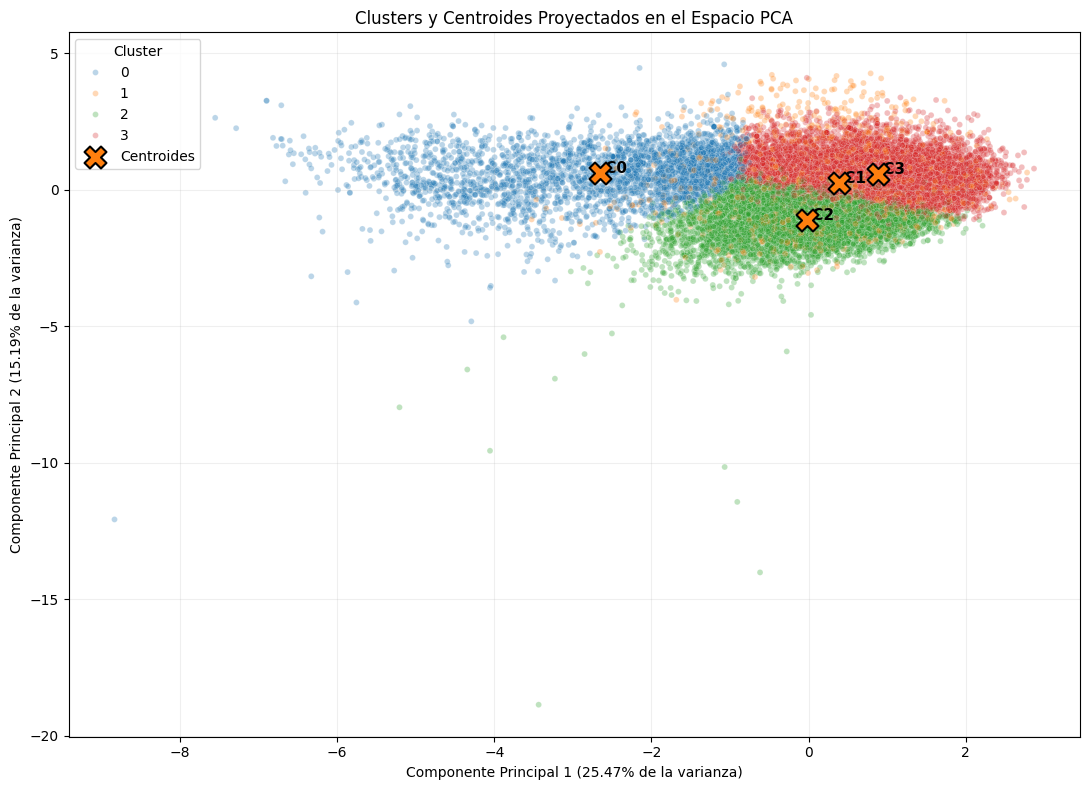

COORDENADAS PCA DE LOS CENTROIDES


,Cluster,Componente Principal 1,Componente Principal 2
0,Cluster 0,-2.661,0.614
1,Cluster 1,0.388,0.260
2,Cluster 2,-0.025,-1.119
3,Cluster 3,0.889,0.577


In [24]:
# =============================================================================
# PROYECCIÓN DE LOS CENTROIDES EN EL ESPACIO PCA
# =============================================================================

"""
Visualización de los clusters y sus centroides dentro del espacio reducido
generado mediante PCA.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque proyecta tanto las observaciones como los centroides de K-Means
sobre los dos primeros componentes principales para facilitar su
visualización en un plano de dos dimensiones.

El procedimiento realiza los siguientes pasos:

1. Toma los centroides originales calculados por K-Means.

2. Proyecta esos centroides sobre el espacio PCA de dos dimensiones mediante
   `pca_2d.transform()`.

3. Guarda las coordenadas de cada centroide en una tabla con:
   - Componente Principal 1;
   - Componente Principal 2.

4. Grafica las canciones en el espacio formado por PC1 y PC2.

5. Colorea las observaciones según el cluster asignado previamente por
   K-Means.

6. Superpone los centroides proyectados utilizando una marca "X" de mayor
   tamaño para facilitar su identificación.

7. Etiqueta cada centroide como C0, C1, C2 y C3.

8. Muestra finalmente las coordenadas exactas de los centroides en una tabla
   fuera del gráfico.

¿QUÉ SIGNIFICA PROYECTAR LOS CENTROIDES?

Los centroides originales de K-Means fueron calculados utilizando las nueve
características acústicas estandarizadas.

Por lo tanto, originalmente cada centroide posee nueve coordenadas.

PCA permite transformar ese centroide desde:

    9 dimensiones
         ↓
        PCA
         ↓
    PC1 y PC2

De esta manera, es posible representar visualmente la posición aproximada
del centro de cada cluster en un gráfico bidimensional.

¿QUÉ REPRESENTAN LOS EJES?

El eje horizontal corresponde al:

    Componente Principal 1

y el eje vertical corresponde al:

    Componente Principal 2

Cada eje muestra también el porcentaje de varianza total que explica ese
componente.

En este análisis, PC1 y PC2 representan conjuntamente solo una parte de la
variabilidad total del dataset.

¿QUÉ REPRESENTAN LAS "X" EN EL GRÁFICO?

Cada "X" corresponde a la posición proyectada del centroide de uno de los
clusters.

Por ejemplo:

    C0 -> centroide del Cluster 0
    C1 -> centroide del Cluster 1

La ubicación de estas marcas permite observar de forma aproximada dónde se
encuentra el centro de cada segmento dentro del espacio PCA.

¿PARA QUÉ SIRVE ESTA VISUALIZACIÓN?

Este gráfico permite:

- observar la distribución general de las canciones;
- comparar la posición relativa de los clusters;
- identificar la ubicación de sus centroides;
- analizar visualmente la separación o superposición entre segmentos;
- y complementar la interpretación obtenida mediante centroides y mapas
  de calor.

IMPORTANTE:

Los clusters NO fueron creados utilizando únicamente PC1 y PC2.

K-Means fue entrenado previamente con las nueve características acústicas
estandarizadas.

PCA se utiliza después únicamente para proyectar y visualizar los resultados.

Por esta razón, si dos clusters aparecen parcialmente superpuestos en el
gráfico, esto no significa necesariamente que K-Means los haya segmentado
incorrectamente.

La separación entre ellos puede depender de información presente en otras
dimensiones que no aparecen en esta representación 2D.

Además, las coordenadas mostradas en `df_centroides_pca` son posiciones en
el espacio PCA y NO corresponden a valores originales como tempo,
danceability, acousticness u otras características acústicas.
"""


# =============================================================================
# 1. PROYECTAR LOS CENTROIDES SOBRE LOS DOS COMPONENTES PCA
# =============================================================================

centroides_pca = pca_2d.transform(
    kmeans_final.cluster_centers_
)


# =============================================================================
# 2. CREAR TABLA CON LAS COORDENADAS DE LOS CENTROIDES
# =============================================================================

df_centroides_pca = pd.DataFrame(
    {
        'Cluster': [
            f'Cluster {cluster_id}'
            for cluster_id in range(K_FINAL)
        ],

        'Componente Principal 1': (
            centroides_pca[:, 0]
        ),

        'Componente Principal 2': (
            centroides_pca[:, 1]
        )
    }
)


# =============================================================================
# 3. CREAR FIGURA
# =============================================================================

plt.figure(
    figsize=(11, 8)
)


# =============================================================================
# 4. OBSERVACIONES
# =============================================================================

sns.scatterplot(
    data=df_pca_plot,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='tab10',
    alpha=0.30,
    s=18
)


# =============================================================================
# 5. CENTROIDES
# =============================================================================

plt.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    marker='X',
    s=250,
    edgecolors='black',
    linewidths=1.5,
    label='Centroides',
    zorder=5
)


# =============================================================================
# 6. ETIQUETAR CADA CENTROIDE
# =============================================================================

for cluster_id in range(K_FINAL):

    plt.text(
        centroides_pca[
            cluster_id,
            0
        ],
        centroides_pca[
            cluster_id,
            1
        ],
        f' C{cluster_id}',
        fontsize=11,
        fontweight='bold'
    )


# =============================================================================
# 7. NOMBRES CLAROS DE LOS EJES
# =============================================================================

plt.xlabel(
    "Componente Principal 1 "
    f"({pca_2d.explained_variance_ratio_[0] * 100:.2f}% "
    "de la varianza)"
)


plt.ylabel(
    "Componente Principal 2 "
    f"({pca_2d.explained_variance_ratio_[1] * 100:.2f}% "
    "de la varianza)"
)


plt.title(
    'Clusters y Centroides Proyectados en el Espacio PCA'
)


plt.legend(
    title='Cluster'
)


plt.grid(
    alpha=0.2
)


# =============================================================================
# 8. AJUSTAR FIGURA
# =============================================================================

plt.tight_layout()

plt.show()


# =============================================================================
# 9. MOSTRAR COORDENADAS DE LOS CENTROIDES FUERA DEL GRÁFICO
# =============================================================================

print("=" * 75)
print("COORDENADAS PCA DE LOS CENTROIDES")
print("=" * 75)

display(
    df_centroides_pca.round(3)
)

El gráfico permite visualizar cómo se distribuyen los cuatro clusters al proyectarlos sobre los dos primeros componentes principales.

Se observa que los grupos presentan cierta separación, aunque también existe superposición entre ellos, especialmente en la zona central del gráfico. Esto es esperable, ya que PC1 y PC2 representan en conjunto solo aproximadamente el **40,66% de la varianza total** del dataset.

Los centroides proyectados muestran la posición central aproximada de cada segmento:

- **Cluster 0** se ubica principalmente hacia valores negativos de PC1, mostrando una separación más evidente respecto de los demás.
- **Cluster 1** se posiciona en la zona positiva de PC1 y ligeramente positiva de PC2.
- **Cluster 2** se concentra principalmente en valores negativos de PC2.
- **Cluster 3** se ubica en valores positivos de PC1 y PC2, cercano al Cluster 1 pero con una posición diferenciada.

En general, el gráfico confirma que existen diferencias entre los segmentos, pero también muestra que la separación no puede evaluarse completamente en solo dos dimensiones. Parte de la información que distingue a los clusters se encuentra en los componentes principales restantes.

## Recuperar los centroides en unidades originales

In [25]:
# =============================================================================
# CENTROIDES EN UNIDADES ORIGINALES
# =============================================================================

"""
Conversión de los centroides de K-Means desde la escala estandarizada hacia
las unidades originales de las variables acústicas.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque transforma los centroides calculados por K-Means para que puedan
interpretarse nuevamente en las unidades originales del dataset.

El procedimiento realiza los siguientes pasos:

1. Recupera el objeto `StandardScaler` utilizado previamente dentro del
   pipeline de preprocesamiento.

2. Toma los centroides almacenados en `kmeans_final.cluster_centers_`.

3. Aplica `inverse_transform()` para deshacer la estandarización.

4. Convierte los centroides nuevamente a las unidades originales de cada
   característica acústica.

5. Organiza los resultados en un DataFrame donde:
   - cada fila representa un cluster;
   - cada columna representa una característica acústica.

6. Muestra finalmente los valores redondeados para facilitar su lectura.

¿POR QUÉ ES NECESARIO HACER LA TRANSFORMACIÓN INVERSA?

K-Means fue entrenado utilizando variables estandarizadas mediante
`StandardScaler`.

Por esta razón, los centroides originales del modelo están expresados en
desviaciones estándar respecto del promedio y no directamente en unidades
como:

    duration_ms
    tempo
    loudness
    danceability
    acousticness
    etc.

Aplicar la transformación inversa permite recuperar valores mucho más fáciles
de interpretar desde el punto de vista del negocio.

Por ejemplo:

    tempo = 121

puede interpretarse directamente como aproximadamente 121 BPM.

En cambio, un valor estandarizado como:

    tempo = +0.04

solo indica una posición relativa respecto del promedio.

¿QUÉ REPRESENTAN ESTOS CENTROIDES?

Cada fila representa el perfil central de uno de los clusters encontrados
por K-Means.

Los valores permiten describir de manera concreta cómo es, en promedio, una
canción ubicada cerca del centro de cada segmento.

Esto facilita comparar los clusters utilizando las unidades originales de
las variables.

¿PARA QUÉ SIRVE ESTE ANÁLISIS?

Los centroides en unidades originales permiten:

- interpretar los segmentos de manera más intuitiva;
- comparar características entre clusters;
- construir perfiles acústicos descriptivos;
- apoyar la elaboración de mapas de calor;
- y traducir los resultados del modelo a acciones de negocio.

IMPORTANTE:

Estos valores corresponden a los centroides calculados por K-Means y luego
transformados nuevamente a la escala original.

No deben confundirse con el promedio simple calculado directamente sobre
todas las canciones de cada cluster, aunque ambos valores pueden ser
similares.

Además, la transformación inversa modifica únicamente la escala de los
centroides; no cambia la segmentación ni vuelve a entrenar el modelo.
"""


# =============================================================================
# RECUPERAR STANDARD SCALER
# =============================================================================

scaler_cluster = (
    preprocessor_clustering
    .named_steps['scaler']
)


# =============================================================================
# TRANSFORMACIÓN INVERSA
# =============================================================================

centroides_originales_array = (
    scaler_cluster
    .inverse_transform(
        kmeans_final.cluster_centers_
    )
)


# =============================================================================
# DATAFRAME
# =============================================================================

centroides_originales = pd.DataFrame(
    centroides_originales_array,
    columns=features_cluster,
    index=[
        f'Cluster {cluster_id}'
        for cluster_id in range(K_FINAL)
    ]
)


print("=" * 90)
print("CENTROIDES EN UNIDADES ORIGINALES")
print("=" * 90)

display(
    centroides_originales.round(3)
)

CENTROIDES EN UNIDADES ORIGINALES


,duration_ms,danceability,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Cluster 0,214019.768,0.406,-16.847,0.051,0.820,0.464,0.163,0.241,104.230
Cluster 1,232648.823,0.531,-7.656,0.213,0.369,0.059,0.727,0.495,120.966
Cluster 2,264358.997,0.489,-6.617,0.074,0.123,0.230,0.184,0.310,135.207
Cluster 3,207309.660,0.678,-7.118,0.088,0.301,0.049,0.166,0.666,118.666


Los centroides permiten interpretar cada cluster utilizando nuevamente las unidades originales de las variables acústicas.

- **Cluster 0:** presenta canciones de aproximadamente **3,57 minutos**, con baja `danceability` (0.406), `loudness` muy bajo (-16.85 dB), alta `acousticness` (0.820) y alta `instrumentalness` (0.464). También posee baja `valence` (0.241) y un tempo relativamente bajo (104 BPM).

  **Traducción:** corresponde a un perfil más acústico, instrumental, tranquilo y menos orientado al baile. Puede asociarse a contextos como relajación, estudio o música ambiental.

- **Cluster 1:** presenta canciones de aproximadamente **3,88 minutos**, con valores intermedios de `danceability` (0.531), alta `speechiness` (0.213) y una `liveness` muy elevada (0.727). Su tempo promedio es cercano a 121 BPM.

  **Traducción:** representa un perfil con fuerte presencia de características asociadas a interpretaciones en vivo y contenido hablado. Puede utilizarse para recomendaciones de conciertos, sesiones en vivo o contenido vocal especializado.

- **Cluster 2:** contiene las canciones más largas, con aproximadamente **4,41 minutos**, el mayor `tempo` (135 BPM), baja `acousticness` (0.123) y `loudness` relativamente elevado (-6.62 dB). Su `valence` también es baja (0.310).

  **Traducción:** corresponde a un perfil más rápido, intenso, extenso y poco acústico. Puede relacionarse con usuarios que prefieren música de mayor energía sonora o sesiones de escucha más intensas.

- **Cluster 3:** presenta las canciones más cortas, con aproximadamente **3,46 minutos**, y destaca por la mayor `danceability` (0.678) y `valence` (0.666), junto con una `instrumentalness` muy baja (0.049).

  **Traducción:** representa el perfil más bailable, positivo y orientado a canciones con mayor presencia vocal. Puede ser especialmente útil para playlists de fiesta, buen ánimo, entrenamiento o descubrimiento general.

Los centroides en unidades originales confirman que los cuatro clusters representan perfiles musicales distintos y fácilmente interpretables. Esta transformación facilita traducir los resultados técnicos de K-Means a características concretas del catálogo y permite asociar cada segmento con posibles contextos de consumo y acciones de negocio.

## Popularidad por cluster

In [26]:
# =============================================================================
# ANÁLISIS DE POPULARIDAD POR CLUSTER
# =============================================================================

"""
Análisis posterior de la popularidad de las canciones según el cluster
asignado por K-Means.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque analiza cómo se distribuye la variable `popularity` dentro de
cada uno de los clusters obtenidos previamente.

El procedimiento realiza los siguientes pasos:

1. Agrupa las canciones según el cluster al que fueron asignadas.

2. Analiza la variable `popularity` dentro de cada grupo.

3. Calcula para cada cluster las siguientes estadísticas:

   - cantidad:
     Número de canciones pertenecientes al segmento.

   - media:
     Popularidad promedio de las canciones del cluster.

   - mediana:
     Valor central de popularidad dentro del segmento.

   - desviación:
     Mide qué tan dispersos se encuentran los valores de popularidad respecto
     del promedio.

   - mínimo:
     Menor valor de popularidad observado en el cluster.

   - máximo:
     Mayor valor de popularidad observado en el cluster.

4. Organiza los resultados en una tabla para facilitar la comparación entre
   los segmentos.

¿POR QUÉ SE ANALIZA POPULARITY DESPUÉS DEL CLUSTERING?

La variable `popularity` fue excluida deliberadamente de las características
utilizadas para entrenar K-Means.

Esto permite que los clusters se formen únicamente a partir de las
características acústicas de las canciones.

Posteriormente, `popularity` se utiliza como una variable externa de
caracterización para responder preguntas como:

    ¿Qué segmento presenta mayor popularidad promedio?

    ¿Existen diferencias de popularidad entre los perfiles acústicos
    encontrados?

¿POR QUÉ ES IMPORTANTE ESTA SEPARACIÓN?

Si `popularity` hubiera sido utilizada para formar los clusters, encontrar
posteriormente diferencias de popularidad entre ellos sería parcialmente
esperable, ya que la propia variable habría influido en la segmentación.

Al excluirla del entrenamiento, las diferencias encontradas pueden
interpretarse como una característica posterior de los segmentos acústicos.

¿CÓMO SE INTERPRETAN MEDIA Y MEDIANA?

La media permite comparar el nivel promedio de popularidad entre clusters.

La mediana complementa este análisis mostrando el valor central y es menos
sensible a valores extremadamente altos o bajos.

Si media y mediana son similares, la distribución de popularidad puede ser
relativamente equilibrada.

Si presentan diferencias importantes, podría existir asimetría en la
distribución.

¿PARA QUÉ SIRVE ESTE ANÁLISIS?

Este análisis permite relacionar los perfiles acústicos encontrados mediante
K-Means con una variable relevante para el negocio.

Puede ayudar a identificar:

- qué segmento presenta mayor popularidad;
- qué perfiles acústicos se asocian con canciones más populares;
- qué segmentos podrían priorizarse en recomendaciones o campañas;
- y cuáles representan nichos con menor popularidad promedio.

IMPORTANTE:

Las diferencias de popularidad observadas entre clusters representan
asociaciones descriptivas.

No permiten afirmar que las características acústicas de un cluster causen
directamente una mayor o menor popularidad.

`Popularity` se utiliza únicamente como variable externa para interpretar y
comparar los segmentos obtenidos.
"""


resumen_popularidad = (
    df_resultados_cluster
    .groupby('cluster')['popularity']
    .agg(
        cantidad='count',
        media='mean',
        mediana='median',
        desviacion='std',
        minimo='min',
        maximo='max'
    )
    .round(2)
)


print("=" * 85)
print("POPULARIDAD SEGÚN CLUSTER")
print("=" * 85)

display(
    resumen_popularidad
)

POPULARIDAD SEGÚN CLUSTER


,cantidad,media,mediana,desviacion,minimo,maximo
cluster,,,,,,
0,13870,29.38,27.0,20.42,0,90
1,7277,33.31,34.0,16.13,0,95
2,29505,33.83,34.0,19.84,0,100
3,39089,34.06,35.0,21.75,0,99


El análisis muestra que los Clusters 1, 2 y 3 presentan niveles de popularidad bastante similares, mientras que el Cluster 0 posee valores claramente más bajos.

- **Cluster 0:** tiene la menor popularidad promedio, con **29,38 puntos**, y una mediana de **27**.
- **Cluster 1:** alcanza una media de **33,31** y una mediana de **34**.
- **Cluster 2:** presenta una media de **33,83** y una mediana de **34**.
- **Cluster 3:** obtiene la mayor popularidad promedio, con **34,06 puntos**, y una mediana de **35**.

En términos generales, el **Cluster 3** es el segmento con mayor popularidad, aunque la diferencia respecto de los Clusters 1 y 2 es pequeña. El **Cluster 0** sí muestra una popularidad claramente inferior al resto.

Como `popularity` no fue utilizada para construir los clusters, estas diferencias corresponden a una caracterización posterior de los perfiles acústicos y no a una condición impuesta por K-Means.

## ¿Qué géneros predominan en cada segmento?

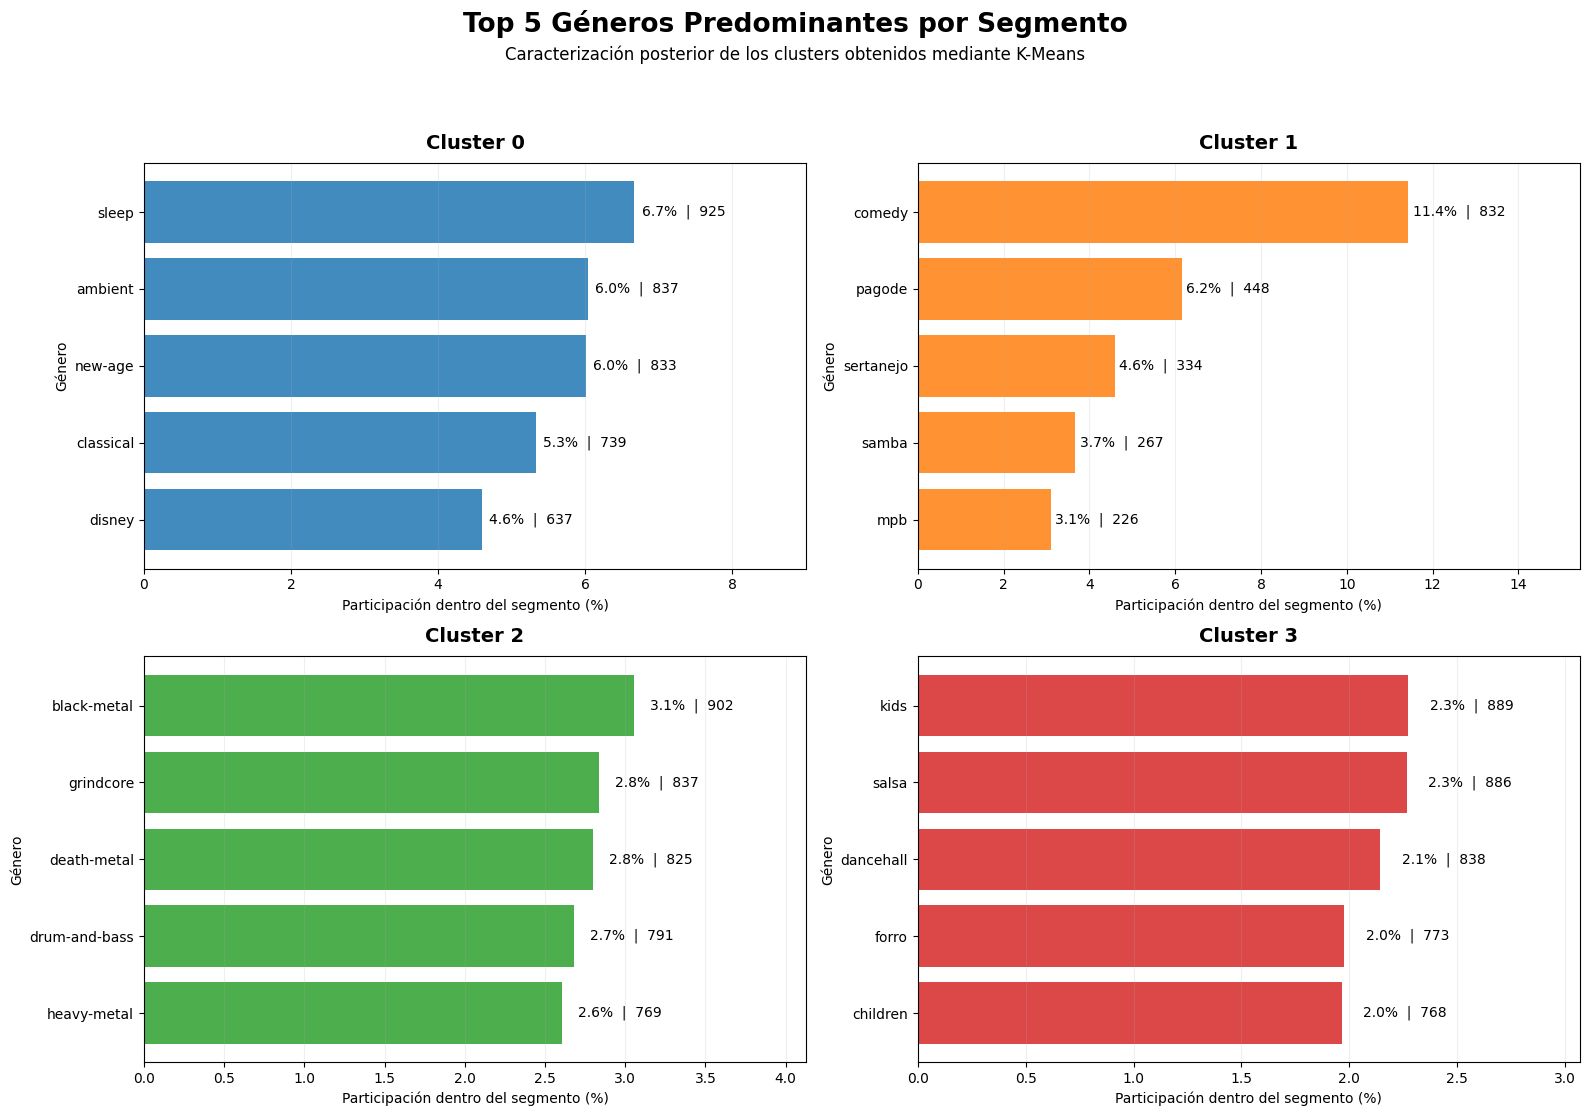

In [27]:
# =============================================================================
# VISUALIZACIÓN DE LOS GÉNEROS PREDOMINANTES POR SEGMENTO
# =============================================================================

"""
Visualización de los géneros predominantes dentro de cada segmento obtenido
mediante K-Means.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque identifica y representa gráficamente los cinco géneros más
frecuentes dentro de cada cluster.

El procedimiento realiza los siguientes pasos:

1. Recorre cada cluster obtenido por K-Means.

2. Filtra las canciones pertenecientes a ese segmento.

3. Cuenta cuántas veces aparece cada valor de `track_genre`.

4. Selecciona los cinco géneros más frecuentes de cada cluster.

5. Calcula qué porcentaje representan esos géneros dentro del total de
   canciones del segmento.

6. Guarda los resultados en un nuevo DataFrame para facilitar su análisis.

7. Construye una figura con cuatro paneles, uno por cluster.

8. En cada panel muestra:
   - los cinco géneros más frecuentes;
   - su porcentaje dentro del segmento;
   - y la cantidad de canciones asociadas a cada género.

¿POR QUÉ SE ANALIZA `track_genre` DESPUÉS DEL CLUSTERING?

La variable `track_genre` NO fue utilizada para formar los clusters.

Los segmentos fueron construidos únicamente a partir de características
acústicas cuantitativas.

Por lo tanto, el género se utiliza posteriormente como una variable externa
de caracterización para responder preguntas como:

    ¿Qué géneros aparecen con mayor frecuencia en cada segmento?

    ¿La composición por género es coherente con el perfil acústico
    descubierto por K-Means?

¿CÓMO SE INTERPRETA EL PORCENTAJE?

El porcentaje representa la participación de un género dentro de su cluster.

Por ejemplo:

    ambient = 8%

significa que aproximadamente el 8% de las canciones pertenecientes a ese
segmento tienen `ambient` como género conservado.

Este porcentaje se calcula respecto del tamaño total del cluster y no
respecto del dataset completo.

¿PARA QUÉ SIRVE ESTE GRÁFICO?

La visualización permite complementar la interpretación de los centroides
acústicos con información musical más familiar.

Esto ayuda a:

- caracterizar mejor cada segmento;
- comprobar si los géneros predominantes son coherentes con el perfil
  acústico del cluster;
- identificar nichos musicales;
- y traducir los resultados de K-Means a posibles estrategias de
  recomendación, playlists o campañas diferenciadas.

¿POR QUÉ SE UTILIZAN CUATRO PANELES?

Cada panel corresponde a un cluster diferente.

Separarlos permite comparar fácilmente la composición interna de cada
segmento sin mezclar géneros que pertenecen a perfiles acústicos distintos.

IMPORTANTE:

Debido a la deduplicación previa por `track_id`, se conservó una sola
observación por canción.

Por esta razón, `track_genre` representa únicamente el género asociado a la
ocurrencia conservada de cada pista y no necesariamente todas las posibles
clasificaciones de una canción.

Además, que un género sea frecuente dentro de un cluster no significa que
ese género haya determinado la formación del segmento, ya que `track_genre`
no participó en el entrenamiento de K-Means.
"""


# =============================================================================
# 1. CONSTRUIR DATAFRAME CON TOP 5 GÉNEROS POR CLUSTER
# =============================================================================

datos_top_generos = []


for cluster_id in sorted(
    df_resultados_cluster['cluster'].unique()
):

    datos_cluster = (
        df_resultados_cluster[
            df_resultados_cluster['cluster']
            == cluster_id
        ]
    )


    top_generos = (
        datos_cluster['track_genre']
        .value_counts()
        .head(5)
    )


    for genero, cantidad in top_generos.items():

        porcentaje = (
            cantidad
            / len(datos_cluster)
            * 100
        )


        datos_top_generos.append(
            {
                'cluster': cluster_id,
                'genero': genero,
                'cantidad': cantidad,
                'porcentaje': porcentaje
            }
        )


df_top_generos_cluster = pd.DataFrame(
    datos_top_generos
)


# =============================================================================
# 2. CREAR FIGURA
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

axes = axes.flatten()


# Colores diferentes para distinguir visualmente los segmentos
colores_clusters = sns.color_palette(
    'tab10',
    n_colors=K_FINAL
)


# =============================================================================
# 3. GRÁFICO POR CLUSTER
# =============================================================================

for cluster_id, ax in enumerate(axes):

    datos = (
        df_top_generos_cluster[
            df_top_generos_cluster['cluster']
            == cluster_id
        ]
        .sort_values(
            'porcentaje',
            ascending=True
        )
    )


    barras = ax.barh(
        datos['genero'],
        datos['porcentaje'],
        color=colores_clusters[cluster_id],
        alpha=0.85
    )


    # -------------------------------------------------------------------------
    # ETIQUETAS DE PORCENTAJE Y CANTIDAD
    # -------------------------------------------------------------------------

    for barra, porcentaje, cantidad in zip(
        barras,
        datos['porcentaje'],
        datos['cantidad']
    ):

        ax.text(
            barra.get_width() + 0.10,
            barra.get_y() + barra.get_height() / 2,
            f'{porcentaje:.1f}%  |  {cantidad:,}',
            va='center',
            fontsize=10
        )


    # -------------------------------------------------------------------------
    # FORMATO
    # -------------------------------------------------------------------------

    ax.set_title(
        f'Cluster {cluster_id}',
        fontsize=14,
        fontweight='bold',
        pad=10
    )


    ax.set_xlabel(
        'Participación dentro del segmento (%)'
    )


    ax.set_ylabel(
        'Género'
    )


    ax.grid(
        axis='x',
        alpha=0.20
    )


    # Dar espacio para mostrar las etiquetas
    limite_maximo = (
        datos['porcentaje'].max()
        * 1.35
    )

    ax.set_xlim(
        0,
        limite_maximo
    )


# =============================================================================
# 4. TÍTULO GENERAL
# =============================================================================

fig.suptitle(
    'Top 5 Géneros Predominantes por Segmento',
    fontsize=19,
    fontweight='bold',
    y=1.01
)


fig.text(
    0.5,
    0.965,
    'Caracterización posterior de los clusters obtenidos mediante K-Means',
    ha='center',
    fontsize=12
)


# =============================================================================
# 5. AJUSTAR DISEÑO
# =============================================================================

plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.95
    ]
)

plt.show()

La distribución de géneros permite complementar y validar la caracterización acústica obtenida mediante K-Means.

- **Cluster 0:** predominan `sleep` (6,7%), `ambient` (6,0%), `new-age` (6,0%) y `classical` (5,3%). Esto es coherente con el perfil acústico e instrumental identificado previamente, asociado a música más tranquila y de menor intensidad.

- **Cluster 1:** destaca principalmente `comedy` (11,4%), seguido de `pagode` (6,2%), `sertanejo` (4,6%) y `samba` (3,7%). La fuerte presencia de `comedy` resulta consistente con los mayores niveles de `speechiness` y `liveness` encontrados en este segmento.

- **Cluster 2:** predominan géneros como `black-metal` (3,1%), `grindcore` (2,8%), `death-metal` (2,8%), `drum-and-bass` (2,7%) y `heavy-metal` (2,6%). Estos géneros respaldan la caracterización de un segmento más rápido, intenso y menos acústico.

- **Cluster 3:** aparecen con mayor frecuencia `kids` (2,3%), `salsa` (2,3%), `dancehall` (2,1%), `forro` (2,0%) y `children` (2,0%). La presencia de géneros como salsa, dancehall y forro es consistente con los elevados niveles de `danceability` y `valence` del segmento.

En general, los géneros predominantes presentan una relación coherente con los perfiles acústicos descubiertos, lo que fortalece la interpretabilidad de los cuatro segmentos. Sin embargo, los porcentajes individuales son relativamente bajos en varios clusters, por lo que cada segmento continúa siendo diverso y no debe interpretarse como equivalente a un único género.

## caracterizar segmentos

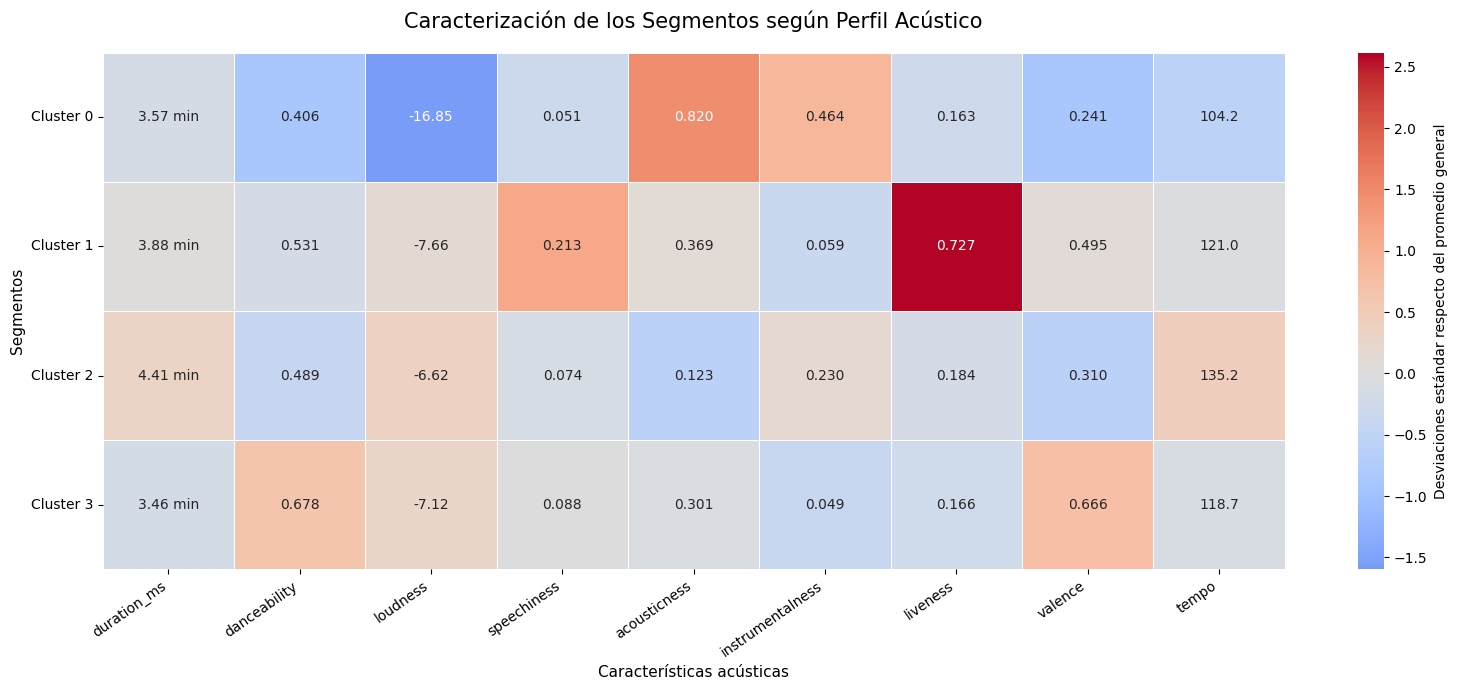

In [28]:
# =============================================================================
# MAPA DE CALOR PARA CARACTERIZACIÓN DE LOS SEGMENTOS
# =============================================================================

"""
Mapa de calor para caracterizar los segmentos a partir de sus perfiles
acústicos.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque combina dos tipos de información para facilitar la interpretación
de los clusters:

1. Utiliza los centroides estandarizados para definir los colores del mapa.
2. Utiliza los centroides en unidades originales para mostrar los valores
   numéricos dentro de cada celda.

De esta manera, el gráfico permite comparar correctamente variables que
originalmente tienen escalas diferentes y, al mismo tiempo, mantener valores
fáciles de interpretar.

¿POR QUÉ LOS COLORES UTILIZAN LOS CENTROIDES ESTANDARIZADOS?

Las características acústicas originales tienen unidades muy distintas.

Por ejemplo:

    duration_ms   -> valores del orden de cientos de miles
    tempo         -> valores cercanos a cientos
    danceability  -> valores entre 0 y 1
    loudness      -> valores negativos en decibeles

Si los colores se construyeran directamente con esos valores, las variables
de mayor magnitud numérica dominarían la escala visual.

Por esta razón, los colores utilizan `centroides_estandarizados`, donde todas
las variables se encuentran expresadas en desviaciones estándar respecto del
promedio general.

¿CÓMO SE INTERPRETAN LOS COLORES?

La escala está centrada en 0.

En términos generales:

    valor cercano a 0
        -> característica similar al promedio general.

    valor positivo
        -> característica relativamente más alta que el promedio.

    valor negativo
        -> característica relativamente más baja que el promedio.

Mientras mayor sea la magnitud del valor estandarizado, mayor es la diferencia
respecto del comportamiento promedio del dataset.

¿QUÉ REPRESENTAN LOS NÚMEROS DENTRO DE LAS CELDAS?

Las anotaciones corresponden a los centroides transformados nuevamente a sus
unidades originales.

Esto permite interpretar los valores de forma más intuitiva.

Por ejemplo:

    duration_ms
        se convierte de milisegundos a minutos.

    tempo
        se muestra en su escala original de BPM.

    loudness
        se muestra en decibeles.

    danceability, acousticness, valence, etc.
        se mantienen en la escala original del dataset.

Por lo tanto:

- el COLOR indica la posición relativa respecto del promedio;
- el NÚMERO indica el valor real del centroide.

¿POR QUÉ SE CONVIERTE duration_ms A MINUTOS?

La duración original se encuentra expresada en milisegundos, lo que dificulta
su interpretación directa.

Por ello se divide por 60.000 para mostrar el resultado en minutos.

Esta conversión afecta únicamente la visualización y no modifica los datos ni
el modelo.

¿PARA QUÉ SIRVE ESTE MAPA DE CALOR?

El gráfico permite identificar de forma rápida:

- las características que más destacan en cada segmento;
- los rasgos relativamente altos y bajos;
- las diferencias entre los clusters;
- y los perfiles acústicos que pueden utilizarse posteriormente para
  caracterizar cada segmento desde una perspectiva de negocio.

Por ejemplo, un cluster puede presentar simultáneamente:

    acousticness alta
    instrumentalness alta
    danceability baja

lo que facilita describirlo como un perfil más acústico e instrumental.

IMPORTANTE:

Los términos "fortaleza" y "debilidad" se utilizan únicamente como una forma
descriptiva de señalar características relativamente altas o bajas.

Un valor alto no significa que una característica sea musicalmente mejor y un
valor bajo no significa que sea peor.

La interpretación debe realizarse considerando conjuntamente el perfil
completo de cada cluster.
"""


# =============================================================================
# 1. MATRIZ UTILIZADA PARA LOS COLORES
# =============================================================================

# Los centroides estandarizados ya representan la distancia respecto
# del promedio global en unidades de desviación estándar.

heatmap_valores = centroides_estandarizados.copy()


# =============================================================================
# 2. CREAR ANOTACIONES CON LOS VALORES ORIGINALES
# =============================================================================

anotaciones = centroides_originales.copy()


# Formatear los valores para que sean fáciles de interpretar
for columna in anotaciones.columns:

    if columna == 'duration_ms':

        # Convertir milisegundos a minutos para facilitar lectura
        anotaciones[columna] = (
            anotaciones[columna]
            / 60000
        ).map(
            lambda x: f"{x:.2f} min"
        )

    elif columna == 'tempo':

        anotaciones[columna] = (
            anotaciones[columna]
            .map(
                lambda x: f"{x:.1f}"
            )
        )

    elif columna == 'loudness':

        anotaciones[columna] = (
            anotaciones[columna]
            .map(
                lambda x: f"{x:.2f}"
            )
        )

    else:

        anotaciones[columna] = (
            anotaciones[columna]
            .map(
                lambda x: f"{x:.3f}"
            )
        )


# =============================================================================
# 3. MAPA DE CALOR
# =============================================================================

plt.figure(
    figsize=(16, 7)
)


sns.heatmap(
    heatmap_valores,
    annot=anotaciones,
    fmt='',
    cmap='coolwarm',
    center=0,
    linewidths=0.7,
    linecolor='white',
    cbar_kws={
        'label':
        'Desviaciones estándar respecto del promedio general'
    }
)


# =============================================================================
# 4. TÍTULOS
# =============================================================================

plt.title(
    'Caracterización de los Segmentos según Perfil Acústico',
    fontsize=15,
    pad=18
)

plt.xlabel(
    'Características acústicas',
    fontsize=11
)

plt.ylabel(
    'Segmentos',
    fontsize=11
)


plt.xticks(
    rotation=35,
    ha='right'
)

plt.yticks(
    rotation=0
)


plt.tight_layout()

plt.show()

El mapa permite interpretar los cuatro clusters utilizando los valores originales de las variables, mientras que los colores muestran si cada característica se encuentra por encima o por debajo del promedio general.

- **Cluster 0 – Perfil acústico, instrumental y tranquilo:** presenta la mayor `acousticness` (0.820) y una alta `instrumentalness` (0.464), junto con baja `danceability` (0.406), baja `valence` (0.241) y menor `loudness` (-16.85 dB).

  **Plan de acción:** utilizar este segmento para playlists y recomendaciones orientadas a relajación, estudio, concentración, descanso y música ambiental. Conviene medir métricas como duración de sesión, tasa de finalización, guardados y baja tasa de skip.

- **Cluster 1 – Perfil en vivo y con mayor presencia hablada:** se diferencia principalmente por una `liveness` muy alta (0.727) y mayor `speechiness` (0.213), lo que indica una fuerte presencia de características asociadas a interpretaciones en vivo o contenido hablado.

  **Plan de acción:** crear recomendaciones especializadas para sesiones en vivo, conciertos, performances y contenidos con mayor componente vocal o hablado. Debido a que corresponde a un perfil más específico, conviene priorizar recomendaciones personalizadas antes que campañas masivas y monitorear retención y tasa de skip.

- **Cluster 2 – Perfil rápido, intenso y poco acústico:** presenta la mayor duración promedio (4.41 minutos) y el mayor `tempo` (135.2 BPM), además de baja `acousticness` (0.123) y menor `valence` (0.310).

  **Plan de acción:** orientar este segmento a usuarios que prefieren música de mayor intensidad, ritmo rápido y canciones más extensas. Puede utilizarse para playlists de entrenamiento intenso, sesiones energéticas o descubrimiento de géneros más agresivos. Se recomienda medir repeticiones, finalización y afinidad por género.

- **Cluster 3 – Perfil bailable y positivo:** destaca por la mayor `danceability` (0.678) y `valence` (0.666), junto con una `instrumentalness` muy baja (0.049). Corresponde al perfil más bailable, positivo y con mayor presencia vocal.

  **Plan de acción:** priorizar este segmento en playlists de fiesta, buen ánimo, entrenamiento, hits y descubrimiento general. También puede ser útil para campañas orientadas a engagement, reproducciones, guardados y compartidos.

En términos generales, la segmentación permite aplicar estrategias diferenciadas según el perfil acústico de cada grupo, evitando tratar todo el catálogo musical de manera homogénea.

# Guardar modelo final

In [29]:
# =============================================================================
# EXPORTACIÓN FINAL DE MODELOS Y RESULTADOS
# =============================================================================

"""
Se almacenan los modelos y resultados finales para garantizar
la reproducibilidad del proceso de segmentación.
"""

os.makedirs(
    "archivos_segmentacion",
    exist_ok=True
)


# Modelo K-Means final
joblib.dump(
    kmeans_final,
    os.path.join(
        "archivos_segmentacion",
        "kmeans_final.joblib"
    )
)


# PCA completo
joblib.dump(
    pca_completo,
    os.path.join(
        "archivos_segmentacion",
        "pca_completo.joblib"
    )
)


# PCA utilizado para visualización
joblib.dump(
    pca_2d,
    os.path.join(
        "archivos_segmentacion",
        "pca_2d.joblib"
    )
)


# Dataset con cluster asignado
df_resultados_cluster.to_csv(
    os.path.join(
        "archivos_segmentacion",
        "resultado_segmentacion.csv"
    ),
    index=False
)


# Evaluación de K
df_evaluacion_k.to_csv(
    os.path.join(
        "archivos_segmentacion",
        "evaluacion_kmeans.csv"
    ),
    index=False
)


# Centroides
centroides_estandarizados.to_csv(
    os.path.join(
        "archivos_segmentacion",
        "centroides_estandarizados.csv"
    )
)

centroides_originales.to_csv(
    os.path.join(
        "archivos_segmentacion",
        "centroides_originales.csv"
    )
)


print("=" * 80)
print("EXPORTACIÓN FINAL COMPLETADA")
print("=" * 80)

for archivo in sorted(
    os.listdir(
        "archivos_segmentacion"
    )
):
    print(
        f" - {archivo}"
    )

EXPORTACIÓN FINAL COMPLETADA
 - X_segmentacion_escalado.csv
 - X_segmentacion_original.csv
 - centroides_estandarizados.csv
 - centroides_originales.csv
 - contexto_segmentacion.csv
 - evaluacion_kmeans.csv
 - kmeans_final.joblib
 - pca_2d.joblib
 - pca_completo.joblib
 - preprocessor_clustering.joblib
 - resultado_segmentacion.csv


# Conclusión

El análisis no supervisado permitió segmentar el catálogo de Spotify a partir
de sus características acústicas y obtener cuatro perfiles musicales
interpretables y potencialmente accionables para el negocio.

Como preparación inicial se estableció una canción única por `track_id`,
reduciendo el dataset desde 114.000 registros a 89.741 observaciones. Para
la formación de los clusters se utilizaron nueve características cuantitativas:
`duration_ms`, `danceability`, `loudness`, `speechiness`, `acousticness`,
`instrumentalness`, `liveness`, `valence` y `tempo`.

`Popularity`, `track_genre` y las demás variables categóricas fueron excluidas
del espacio utilizado por K-Means para evitar que condicionaran directamente
la formación de los segmentos. Asimismo, `energy` fue excluida debido a la
redundancia identificada durante el análisis exploratorio previo.

El preprocesamiento se realizó mediante imputación por mediana y
`StandardScaler`, debido a que K-Means trabaja con distancia euclidiana y las
variables poseen escalas diferentes. Los valores extremos no fueron
winsorizados, ya que durante el EDA se consideraron observaciones plausibles
dentro del dominio musical y potencialmente relevantes para descubrir perfiles
particulares.

La cantidad de clusters se evaluó entre K=1 y K=10. El Método del Codo
identificó **K=4** como una solución adecuada, mientras que el mayor
Silhouette Score se obtuvo para **K=2 (0.2474)**. Para K=4 el Silhouette fue
de **0.1596**, indicando que existe cierto grado de superposición entre los
grupos. Se mantuvo K=4 como solución final porque ofrece una mayor granularidad
para el objetivo de negocio y produjo segmentos con tamaños relevantes y
perfiles acústicos interpretables. Por lo tanto, la solución debe entenderse
como una segmentación útil e interpretable, aunque con separación geométrica
moderada.

Los cuatro segmentos encontrados fueron:

**Cluster 0 – Perfil acústico, instrumental y tranquilo:** concentra 13.870
canciones (15,46%) y presenta alta `acousticness` e `instrumentalness`,
junto con menor `loudness`, `danceability` y `valence`. Los géneros más
frecuentes, como `sleep`, `ambient`, `new-age` y `classical`, refuerzan esta
interpretación. Este grupo resulta apropiado para recomendaciones relacionadas
con relajación, estudio, concentración y música ambiental.

**Cluster 1 – Perfil en vivo y con mayor presencia hablada:** contiene 7.277
canciones (8,11%) y destaca principalmente por una elevada `liveness` y
`speechiness`. Géneros como `comedy`, `pagode`, `sertanejo` y `samba`
complementan esta caracterización. Este segmento concentra además un
**47,01% de observaciones con al menos una característica situada a más de
tres desviaciones estándar del promedio**, por lo que debe interpretarse con
especial cautela. Estos valores fueron conservados al considerarse casos
plausibles del dominio musical y pueden representar un nicho real del catálogo.

**Cluster 2 – Perfil rápido, intenso y poco acústico:** reúne 29.505 canciones
(32,88%), presenta el mayor `tempo`, mayor duración y baja `acousticness`.
La presencia de géneros como `black-metal`, `grindcore`, `death-metal`,
`drum-and-bass` y `heavy-metal` resulta coherente con este perfil. Puede
utilizarse para recomendaciones orientadas a usuarios interesados en música
más rápida, extensa e intensa.

**Cluster 3 – Perfil bailable y positivo:** es el segmento más numeroso, con
39.089 canciones (43,56%), y se caracteriza por los mayores niveles de
`danceability` y `valence`, junto con baja `instrumentalness`. Géneros como
`salsa`, `dancehall` y `forro` respaldan parcialmente este comportamiento.
Este segmento puede ser especialmente útil para playlists de fiesta, buen
ánimo, entrenamiento y descubrimiento general.

La variable `popularity` fue incorporada únicamente después de construir los
clusters. El Cluster 3 presentó la mayor popularidad promedio (34,06),
seguido por los Clusters 2 (33,83) y 1 (33,31), mientras que el Cluster 0
obtuvo un promedio inferior (29,38). Estas diferencias corresponden a
asociaciones descriptivas y no permiten establecer que pertenecer a un
determinado cluster cause una mayor o menor popularidad.

PCA permitió complementar el análisis dimensional. PC1 explica el 25,47% de
la varianza y PC2 el 15,19%, por lo que la representación bidimensional
conserva solo el **40,66% de la variabilidad total**. En consecuencia, el
gráfico PCA fue utilizado únicamente como herramienta de visualización y no
como base para formar los clusters. Para representar al menos el 80% de la
varianza se requieren 6 componentes, para superar el 90% se requieren 7 y
para superar el 95% se requieren 8, confirmando que la estructura acústica del
dataset es multidimensional.

Desde la perspectiva del negocio, la principal utilidad de la segmentación es
permitir estrategias diferenciadas en lugar de tratar todo el catálogo como
un conjunto homogéneo. Los perfiles encontrados pueden servir como base para
construcción de playlists, recomendaciones personalizadas, descubrimiento de
contenido y campañas específicas. Su impacto real debería validarse
posteriormente mediante métricas de interacción como tasa de skip,
finalización, guardados, repeticiones y duración de sesión.

En conclusión, **K-Means con K=4 permitió obtener una segmentación
acústicamente interpretable, representativa en tamaño y útil como base para
acciones de negocio, aunque con una separación geométrica moderada entre
algunos grupos**. Los resultados no deben considerarse categorías absolutas,
sino perfiles exploratorios que ayudan a comprender la diversidad del catálogo
y que pueden ser refinados y validados posteriormente con información real de
comportamiento de usuarios.

Como limitaciones principales, debe considerarse que la deduplicación conserva
una sola ocurrencia y un solo `track_genre` por canción, que el Cluster 1 está
fuertemente influido por observaciones extremas legítimas y que la popularidad
puede estar afectada por factores externos como exposición o promoción. Estas
consideraciones no invalidan la segmentación, pero establecen el contexto
adecuado para interpretar y utilizar sus resultados.

# Metodología CRISP-DM

El proceso de segmentación se estructura siguiendo las etapas de CRISP-DM:

**Business Understanding:** identificar segmentos acústicos dentro del catálogo
que permitan apoyar estrategias diferenciadas de recomendación, playlists y
personalización.

**Data Understanding:** análisis previo de calidad de datos, duplicados,
distribuciones, valores extremos y relaciones entre variables.

**Data Preparation:** deduplicación por `track_id`, selección de características
acústicas, exclusión de variables no apropiadas para la distancia euclidiana,
imputación por mediana y estandarización mediante StandardScaler.

**Modeling:** aplicación de K-Means y evaluación de distintos valores de K.

**Evaluation:** análisis mediante Inercia, Método del Codo, Silhouette Score,
tamaño de clusters, centroides, valores extremos, PCA y caracterización externa
mediante popularidad y género.

**Deployment / Business Use:** generación de perfiles y planes de acción
orientados a recomendaciones, playlists y estrategias diferenciadas por segmento.

## Problema de negocio

El catálogo de Spotify contiene canciones con perfiles acústicos muy diversos.
Tratar todo el catálogo como un conjunto homogéneo limita la capacidad de
diseñar recomendaciones, playlists y estrategias diferenciadas.

## Objetivo de segmentación

Identificar grupos de canciones con perfiles acústicos similares mediante
aprendizaje no supervisado, con el propósito de generar segmentos interpretables
y accionables para el negocio.

## KPIs de evaluación

**KPIs técnicos**
- Inercia y punto de codo para seleccionar una cantidad adecuada de clusters.
- Silhouette Score como medida complementaria de cohesión y separación.
- Distribución porcentual de canciones por cluster.
- Varianza explicada acumulada mediante PCA.

**KPIs de negocio propuestos para una etapa de despliegue**
- Tasa de skip por segmento.
- Tasa de finalización.
- Guardados en playlists.
- Reproducciones repetidas.
- Duración de sesión.
- Engagement con recomendaciones personalizadas.

Los KPIs de negocio corresponden a métricas futuras de validación y no están
disponibles directamente en el dataset utilizado.

## Consideraciones éticas y limitaciones

La segmentación se realiza sobre características de canciones y no sobre
atributos personales de usuarios.

Sin embargo, los resultados deben interpretarse considerando posibles sesgos
del dataset. La variable `popularity` puede estar influida por exposición,
promoción y comportamiento previo de la plataforma, por lo que no debe
interpretarse como una medida objetiva de calidad musical.

Asimismo, la deduplicación por `track_id` conserva una sola categoría
`track_genre`, perdiendo parte de la naturaleza multigénero de algunas pistas.

Los segmentos deben utilizarse como apoyo para recomendaciones y no como
clasificaciones absolutas. Su utilidad debería validarse posteriormente con
métricas reales de interacción de usuarios y pruebas controladas.